# L1: Getting Started with Dates and Times in Pandas

In [1]:
import pandas as pd

# Generate 5 daily timestamps
dates = pd.date_range(start='2023-01-01', periods=5, freq='D')
print(dates)

# Create a DataFrame indexed by these dates
df = pd.DataFrame({'value': [10, 20, 15, 25, 30]}, index=dates)
df

DatetimeIndex(['2023-01-01', '2023-01-02', '2023-01-03', '2023-01-04',
               '2023-01-05'],
              dtype='datetime64[ns]', freq='D')


,value
2023-01-01,10
2023-01-02,20
2023-01-03,15
2023-01-04,25
2023-01-05,30


We made a `DatetimeIndex` of 5 `Timestamps` and assigned it to a DataFrame, turning that DataFrame a time series.

In [2]:
ts = pd.Timestamp('2023-07-01')
ts

Timestamp('2023-07-01 00:00:00')

Creating a new `Timestamp` instance.

In [3]:
print(ts.year) # prints the year  
print(ts.month)    # prints the month
print(ts.day_name())    # prints the day name

2023
7
Saturday


We can use parts of a `Timestamp` to drive features or filters.

In [4]:
p = pd.Period('2023-07', freq='M')
print(p) 
print(p.to_timestamp(how='end'))  # 2023-07-31 23:59:59.999999999

2023-07
2023-07-31 23:59:59.999999999


A `Period` basically bundles all the `Timestamp` in a given span.

In [5]:
from pandas.tseries.offsets import DateOffset, MonthEnd

# Period arithmetic: add 2 months
p_jan = pd.Period('2023-01', freq='M')
print(p_jan + 2)         # 2023-03

# Timestamp arithmetic: roll forward to next month end
ts = pd.Timestamp('2023-01-31')
print(ts + MonthEnd(1))  # 2023-02-28 00:00:00
print(ts + DateOffset(months=2))  # 2023-03-31 00:00:00

2023-03
2023-02-28 00:00:00
2023-03-31 00:00:00


We can do arithmetic with `Timestamp` & `Periods`, like adding or subtracting a month.

In [6]:
# Daily timestamps
daily = pd.date_range('2023-01-01', periods=5, freq='D')
print(daily)

# Monthly periods
periods = pd.period_range('2023-01', periods=5, freq='M')
print(periods)

DatetimeIndex(['2023-01-01', '2023-01-02', '2023-01-03', '2023-01-04',
               '2023-01-05'],
              dtype='datetime64[ns]', freq='D')
PeriodIndex(['2023-01', '2023-02', '2023-03', '2023-04', '2023-05'], dtype='period[M]')


Creating sequence of dates and periods.

`date_range` → calendar of dates / datetimes

`period_range` → calendar of time buckets (months/quarters/years, etc.)



In [7]:
dt_idx = pd.date_range('2023-01-01', periods=5, freq='D')
pr_idx = dt_idx.to_period('D')
print(pr_idx)

PeriodIndex(['2023-01-01', '2023-01-02', '2023-01-03', '2023-01-04',
             '2023-01-05'],
            dtype='period[D]')


Converting `DatetimeIndex` to `PeriodIndex`.

In [8]:
import numpy as np

dates = pd.date_range('2023-01-01', periods=5, freq='D')
df_ts = pd.DataFrame(
    {'A': range(5), 'B': np.random.randn(5)},
    index=dates
)
print(df_ts)

            A         B
2023-01-01  0  1.209408
2023-01-02  1 -0.306635
2023-01-03  2 -1.553166
2023-01-04  3  0.340103
2023-01-05  4 -0.502051


In [9]:
import numpy as np

dates = pd.date_range('2023-01-01', periods=5, freq='h')
df_ts = pd.DataFrame(
    {'A': range(5), 'B': np.random.randn(5)},
    index=dates
)
print(df_ts)

                     A         B
2023-01-01 00:00:00  0 -0.372660
2023-01-01 01:00:00  1  1.006169
2023-01-01 02:00:00  2  1.732208
2023-01-01 03:00:00  3 -0.328669
2023-01-01 04:00:00  4 -0.176474


In [10]:
import numpy as np

dates = pd.date_range('2023-01-01', periods=5, freq='W')
df_ts = pd.DataFrame(
    {'A': range(5), 'B': np.random.randn(5)},
    index=dates
)
print(df_ts)

            A         B
2023-01-01  0 -0.331682
2023-01-08  1 -1.019446
2023-01-15  2 -1.214267
2023-01-22  3  0.735490
2023-01-29  4 -0.751261


In [11]:
import numpy as np

dates = pd.date_range('2023-01-01', periods=6, freq='B')
df_ts = pd.DataFrame(
    {'A': range(6), 'B': np.random.randn(6)},
    index=dates
)
print(df_ts)

            A         B
2023-01-02  0 -0.395083
2023-01-03  1 -0.551452
2023-01-04  2 -0.342138
2023-01-05  3 -0.286304
2023-01-06  4  0.784927
2023-01-09  5  0.485203


#### 🧪 Exercise: Hands-On with Dates, Timestamps & Periods in Pandas

In [12]:
import pandas as pd
import numpy as np
from pandas.tseries.offsets import MonthEnd, DateOffset

# Provided data
date_strings = [
    '2023-01-01', '2023-01-02', '2023-01-03',
    '2023-01-04', '2023-01-05'
]
values = [10, 20, 15, 25, 30]

In [13]:
dates = pd.to_datetime(date_strings)
df = pd.DataFrame({'value': values}, index=dates)
print("Original DataFrame:")
df

Original DataFrame:


,value
2023-01-01,10
2023-01-02,20
2023-01-03,15
2023-01-04,25
2023-01-05,30


In [14]:
ts_0 = df.index[0]
year = ts_0.year
month = ts_0.month
day_name = ts_0.day_name()

df['year'] = year
df['month'] = month
df['weekday'] = day_name
df

,value,year,month,weekday
2023-01-01,10,2023,1,Sunday
2023-01-02,20,2023,1,Sunday
2023-01-03,15,2023,1,Sunday
2023-01-04,25,2023,1,Sunday
2023-01-05,30,2023,1,Sunday


In [15]:
p = pd.Period('2023-01', freq='M')
p2 = p + 2
p2_ts = p2.to_timestamp(how='end')

p2_ts

Timestamp('2023-03-31 23:59:59.999999999')

In [16]:
last_ts = df.index[-1]
rf_me = last_ts + MonthEnd(1)
rf_dos = last_ts + DateOffset(months=2)

In [17]:
daily = pd.date_range('2023-02-01', periods=7, freq='D')
print("Daily Timestamps:", daily)

monthly = pd.period_range('2023-02', periods=6, freq='M')
print("Monthly Periods:", monthly)

Daily Timestamps: DatetimeIndex(['2023-02-01', '2023-02-02', '2023-02-03', '2023-02-04',
               '2023-02-05', '2023-02-06', '2023-02-07'],
              dtype='datetime64[ns]', freq='D')
Monthly Periods: PeriodIndex(['2023-02', '2023-03', '2023-04', '2023-05', '2023-06', '2023-07'], dtype='period[M]')


In [18]:
ts_to_p = daily.to_period('D')
print(ts_to_p)

PeriodIndex(['2023-02-01', '2023-02-02', '2023-02-03', '2023-02-04',
             '2023-02-05', '2023-02-06', '2023-02-07'],
            dtype='period[D]')


In [19]:
monthly_index = pd.period_range('2023-01', periods=6, freq='M')
df2 = pd.DataFrame({
    'A': range(6),
    'B': np.random.randn(6)
}, index=monthly_index)
df2

,A,B
2023-01,0,-0.263651
2023-02,1,-0.077862
2023-03,2,1.374947
2023-04,3,0.702137
2023-05,4,-1.037380
2023-06,5,0.170596


In [20]:
ts_bd = pd.date_range('2023-03-01', '2023-03-31', freq='B')
ts_bd

DatetimeIndex(['2023-03-01', '2023-03-02', '2023-03-03', '2023-03-06',
               '2023-03-07', '2023-03-08', '2023-03-09', '2023-03-10',
               '2023-03-13', '2023-03-14', '2023-03-15', '2023-03-16',
               '2023-03-17', '2023-03-20', '2023-03-21', '2023-03-22',
               '2023-03-23', '2023-03-24', '2023-03-27', '2023-03-28',
               '2023-03-29', '2023-03-30', '2023-03-31'],
              dtype='datetime64[ns]', freq='B')

# L2: Indexing & Transforming Real-World Time Series

In [21]:
dates = pd.date_range('2023-01-01', periods=6, freq='B')
df_ts = pd.DataFrame(
    {'A': range(6), 'B': np.random.randn(6)},
    index=dates
)
print(df_ts)

            A         B
2023-01-02  0 -0.829533
2023-01-03  1  0.443657
2023-01-04  2  0.495148
2023-01-05  3  0.496843
2023-01-06  4  3.389299
2023-01-09  5  0.290631


In [22]:
# Example: downsample daily data to monthly average
monthly = df_ts.resample('ME').mean()

# Example: upsample daily data to hourly (will introduce gaps)
hourly = df_ts.resample('h').asfreq()

print("Monthly Resampled DataFrame:")
print(monthly)
print("Hourly Resampled DataFrame:")
print(hourly)

Monthly Resampled DataFrame:
              A         B
2023-01-31  2.5  0.714341
Hourly Resampled DataFrame:
                       A         B
2023-01-02 00:00:00  0.0 -0.829533
2023-01-02 01:00:00  NaN       NaN
2023-01-02 02:00:00  NaN       NaN
2023-01-02 03:00:00  NaN       NaN
2023-01-02 04:00:00  NaN       NaN
...                  ...       ...
2023-01-08 20:00:00  NaN       NaN
2023-01-08 21:00:00  NaN       NaN
2023-01-08 22:00:00  NaN       NaN
2023-01-08 23:00:00  NaN       NaN
2023-01-09 00:00:00  5.0  0.290631

[169 rows x 2 columns]


#### Working with stimulated Google(GOOG) data

In [23]:
goog = pd.read_csv(
    "data/goog_simulated.csv",              # local file after download
    parse_dates=["date"],
    index_col="date"
)

print(goog.info())

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 523 entries, 2020-01-01 to 2021-12-31
Data columns (total 1 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   close_price  523 non-null    float64
dtypes: float64(1)
memory usage: 8.2 KB
None


Converting string dates to `datetime64`

In [24]:
goog_raw = pd.read_csv(
    "data/goog_simulated.csv"               # local file after download
)
print(goog_raw.dtypes)

goog_raw["date"] = pd.to_datetime(goog_raw["date"])
print('-'*80)
print(goog_raw.dtypes)

date            object
close_price    float64
dtype: object
--------------------------------------------------------------------------------
date           datetime64[ns]
close_price           float64
dtype: object


In [25]:
goog_raw.set_index("date", inplace=True)

In [26]:
goog_raw.index

DatetimeIndex(['2020-01-01', '2020-01-02', '2020-01-03', '2020-01-06',
               '2020-01-07', '2020-01-08', '2020-01-09', '2020-01-10',
               '2020-01-13', '2020-01-14',
               ...
               '2021-12-20', '2021-12-21', '2021-12-22', '2021-12-23',
               '2021-12-24', '2021-12-27', '2021-12-28', '2021-12-29',
               '2021-12-30', '2021-12-31'],
              dtype='datetime64[ns]', name='date', length=523, freq=None)

Plotting the time series data

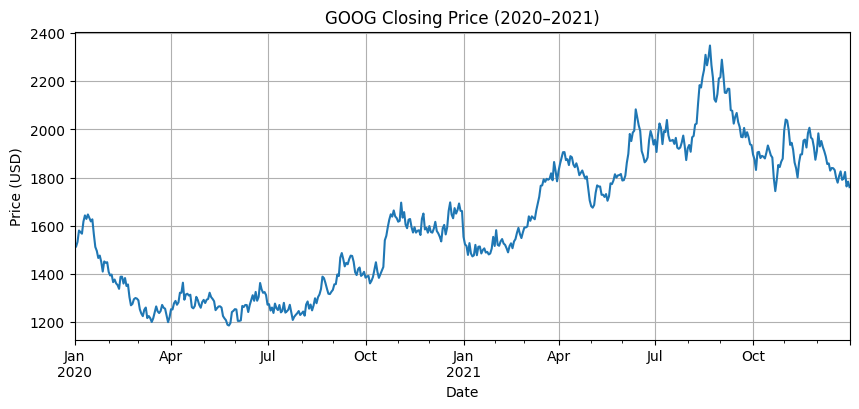

In [27]:
import matplotlib.pyplot as plt

goog["close_price"].plot(
    title="GOOG Closing Price (2020–2021)",
    figsize=(10, 4)
)
plt.ylabel("Price (USD)")
plt.xlabel("Date")
plt.grid(True)
plt.show()

Slicing the time series data

In [28]:
goog.head()

,close_price
date,
2020-01-01,1515.651425
2020-01-02,1512.218041
2020-01-03,1532.563075
2020-01-06,1580.012143
2020-01-07,1573.402846


In [29]:
# All of 2020
goog_2020 = goog["2020":"2020"]
print(goog_2020.shape)
print(goog_2020.head(), '\n\n')
print(goog_2020.tail())

(262, 1)
            close_price
date                   
2020-01-01  1515.651425
2020-01-02  1512.218041
2020-01-03  1532.563075
2020-01-06  1580.012143
2020-01-07  1573.402846 


            close_price
date                   
2020-12-25  1650.145081
2020-12-28  1665.617482
2020-12-29  1692.255171
2020-12-30  1661.729241
2020-12-31  1660.581805


In [30]:
# Q1 2021 (Jan–Mar)
q1_2021 = goog["2021-01":"2021-03"]
print(q1_2021.shape)
print(q1_2021.head(), '\n\n')
print(q1_2021.tail())

(64, 1)
            close_price
date                   
2021-01-01  1553.764305
2021-01-04  1522.708048
2021-01-05  1515.777651
2021-01-06  1478.708303
2021-01-07  1527.724860 


            close_price
date                   
2021-03-25  1817.390983
2021-03-26  1788.559141
2021-03-29  1864.300588
2021-03-30  1827.722363
2021-03-31  1784.252230


Choosing particular records

In [31]:
# Closing price on January 15, 2021
print(goog.loc['2021-01-15', 'close_price'])


1512.576969308959


In [32]:
# All data on January 15, 2021 (returns a Series)
print(goog.loc['2021-01-15'])

close_price    1512.576969
Name: 2021-01-15 00:00:00, dtype: float64


In [33]:
# Closing prices from Jan 1 to Jan 31, 2021
jan2021 = goog.loc['2021-01-01':'2021-01-31', 'close_price']
print(jan2021.shape)
jan2021.head()

(21,)


date
2021-01-01    1553.764305
2021-01-04    1522.708048
2021-01-05    1515.777651
2021-01-06    1478.708303
2021-01-07    1527.724860
Name: close_price, dtype: float64

Dummy data to present how to select multiple columns

In [34]:
# Suppose you had columns ['open_price','close_price']
goog_sample = goog.copy()
goog_sample['open_price'] = goog_sample['close_price'] * 0.98  # dummy open

subset = goog_sample.loc['2021-06-01':'2021-06-15', ['open_price', 'close_price']]
subset.head()

,open_price,close_price
date,,
2021-06-01,1751.679972,1787.428543
2021-06-02,1753.414492,1789.198461
2021-06-03,1771.755148,1807.913416
2021-06-04,1824.062448,1861.288213
2021-06-07,1859.969877,1897.928446


In [35]:
# Assume goog has a DatetimeIndex of business days (freq='B')
# 1️⃣ Convert to a daily frequency (calendar days)
goog_daily = goog.asfreq('D')

# Inspect the first 10 rows
goog_daily.head(10)

,close_price
date,
2020-01-01,1515.651425
2020-01-02,1512.218041
2020-01-03,1532.563075
2020-01-04,NaN
2020-01-05,NaN
2020-01-06,1580.012143
2020-01-07,1573.402846
2020-01-08,1566.821712
2020-01-09,1617.092022


In [36]:
# Check that Pandas now recognizes a daily frequency
print("Frequency attribute:", goog_daily.index.freq)

Frequency attribute: <Day>


In [37]:
goog_monthly_end = goog_daily.asfreq('ME')
goog_monthly_end.head()

,close_price
date,
2020-01-31,1448.515094
2020-02-29,NaN
2020-03-31,1219.677896
2020-04-30,1283.067523
2020-05-31,NaN


Dealing with missing/NaN values created during upsampling.

In [38]:
# Start with the business-day series
goog_biz = goog.asfreq('B')      # has values only on business days

# Upsample to hourly frequency
goog_hourly = goog_biz.asfreq('h')

# Inspect the first 10 rows
print(goog_hourly.head(10))
# Count how many hourly slots are missing
num_missing = goog_hourly['close_price'].isna().sum()
print("Missing hourly data points:", num_missing)

                     close_price
date                            
2020-01-01 00:00:00  1515.651425
2020-01-01 01:00:00          NaN
2020-01-01 02:00:00          NaN
2020-01-01 03:00:00          NaN
2020-01-01 04:00:00          NaN
2020-01-01 05:00:00          NaN
2020-01-01 06:00:00          NaN
2020-01-01 07:00:00          NaN
2020-01-01 08:00:00          NaN
2020-01-01 09:00:00          NaN
Missing hourly data points: 16998


Switching to `Business Day` frequency.

In [39]:
# Suppose we’ve already made a daily series
goog_daily = goog.asfreq('D')
print("Original daily index sample:")
print(goog_daily.head(7))

Original daily index sample:
            close_price
date                   
2020-01-01  1515.651425
2020-01-02  1512.218041
2020-01-03  1532.563075
2020-01-04          NaN
2020-01-05          NaN
2020-01-06  1580.012143
2020-01-07  1573.402846


In [40]:
goog_biz = goog_daily.asfreq('B')
print("After applying business-day freq:")
print(goog_biz.head(7))

After applying business-day freq:
            close_price
date                   
2020-01-01  1515.651425
2020-01-02  1512.218041
2020-01-03  1532.563075
2020-01-06  1580.012143
2020-01-07  1573.402846
2020-01-08  1566.821712
2020-01-09  1617.092022


Identifying missing values in the data.

In [41]:
# Assume goog_biz is your business-day–indexed DataFrame

# Identify rows with missing close_price
missing_biz = goog_biz[goog_biz['close_price'].isna()]

# View the first few missing entries
print(missing_biz.head())
# How many business days have no trading data?
print("Number of missing business days:", missing_biz.shape[0])

Empty DataFrame
Columns: [close_price]
Index: []
Number of missing business days: 0


#### 🧪 Exercise: Structuring Time Series – Indexing & Visualizing Air Quality Trends

In [42]:
air_q_df = pd.read_csv("data/air_quality_trends_simulated.csv", parse_dates=["date"], index_col="date")

In [43]:
air_q_df.index

DatetimeIndex(['2023-01-01', '2023-01-02', '2023-01-03', '2023-01-04',
               '2023-01-05', '2023-01-06', '2023-01-07', '2023-01-08',
               '2023-01-09', '2023-01-10',
               ...
               '2023-12-22', '2023-12-23', '2023-12-24', '2023-12-25',
               '2023-12-26', '2023-12-27', '2023-12-28', '2023-12-29',
               '2023-12-30', '2023-12-31'],
              dtype='datetime64[ns]', name='date', length=365, freq=None)

In [44]:
air_q_df.info

<bound method DataFrame.info of                 ozone       pm25        co
date                                      
2023-01-01  57.440675  18.758119  0.951169
2023-01-02  65.759468  26.725029  0.814028
2023-01-03  60.138169  16.970760  0.801403
2023-01-04  57.244159  32.121332  0.686995
2023-01-05  51.182740  25.700751  0.945567
...               ...        ...       ...
2023-12-27  39.356545  31.351175  0.789647
2023-12-28  75.199198  25.723543  0.532305
2023-12-29  57.190298  34.620463  1.230391
2023-12-30  52.845571  27.778474  1.373524
2023-12-31  74.102071  15.936339  0.510277

[365 rows x 3 columns]>

In [45]:
air_q_df.head()

,ozone,pm25,co
date,,,
2023-01-01,57.440675,18.758119,0.951169
2023-01-02,65.759468,26.725029,0.814028
2023-01-03,60.138169,16.970760,0.801403
2023-01-04,57.244159,32.121332,0.686995
2023-01-05,51.182740,25.700751,0.945567


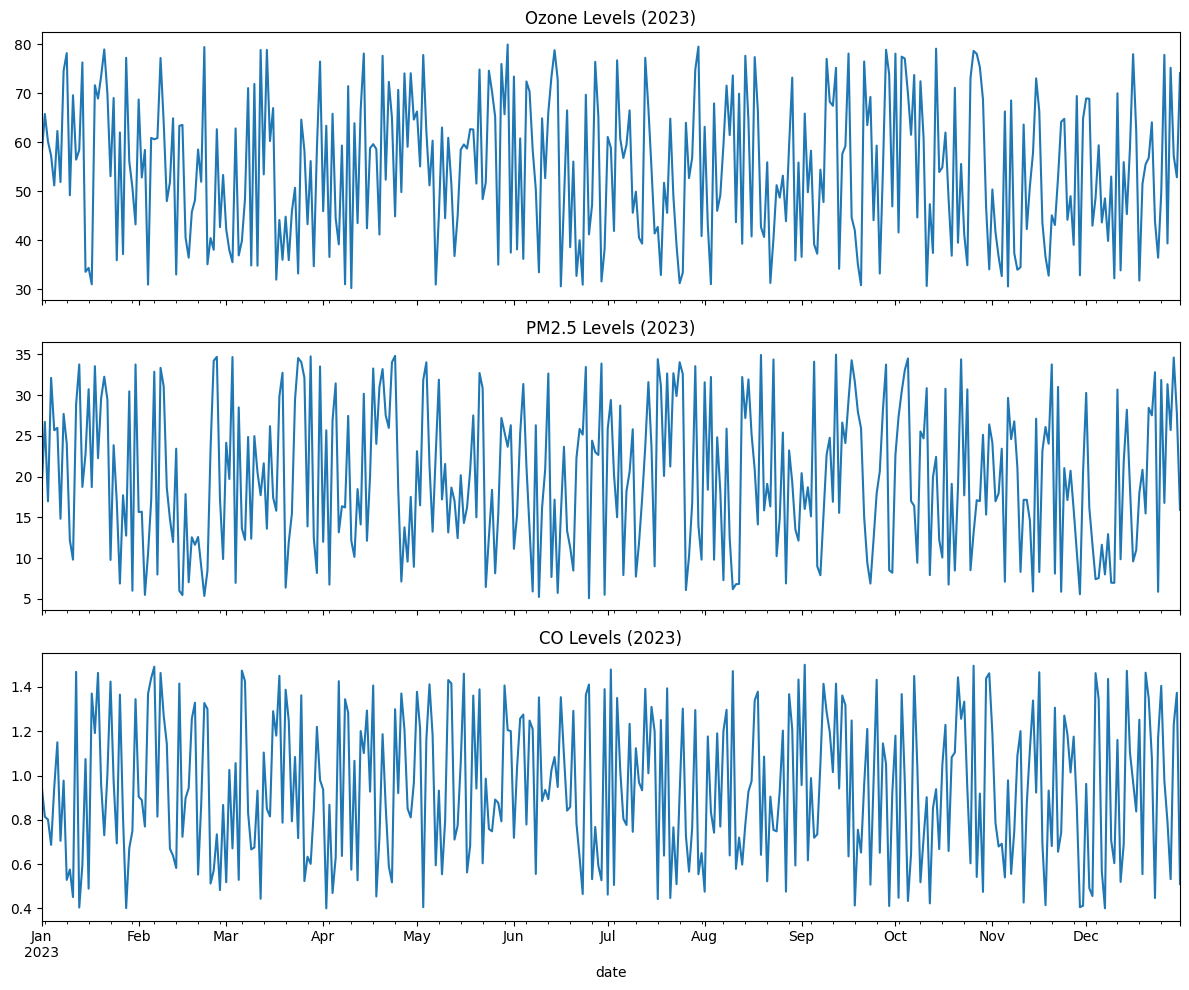

In [46]:
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(12, 10), sharex=True)
air_q_df["ozone"].plot(ax=axes[0], title="Ozone Levels (2023)")
air_q_df["pm25"].plot(ax=axes[1], title="PM2.5 Levels (2023)")
air_q_df["co"].plot(ax=axes[2], title="CO Levels (2023)")
plt.tight_layout()
plt.show()

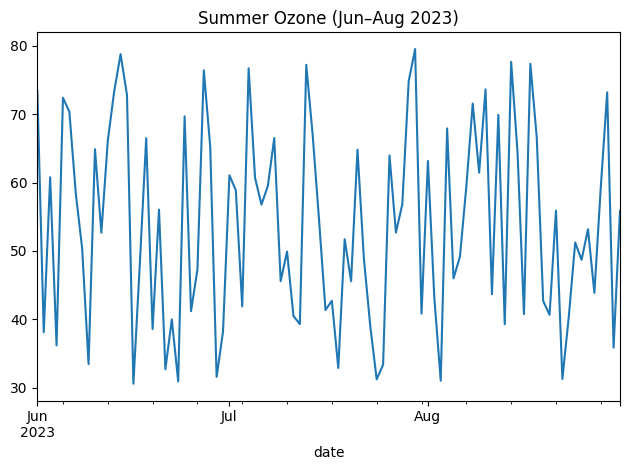

In [47]:
summer_ozone = air_q_df["2023-06":"2023-08"]["ozone"]
summer_ozone.plot(title="Summer Ozone (Jun–Aug 2023)")
plt.tight_layout()
plt.show()

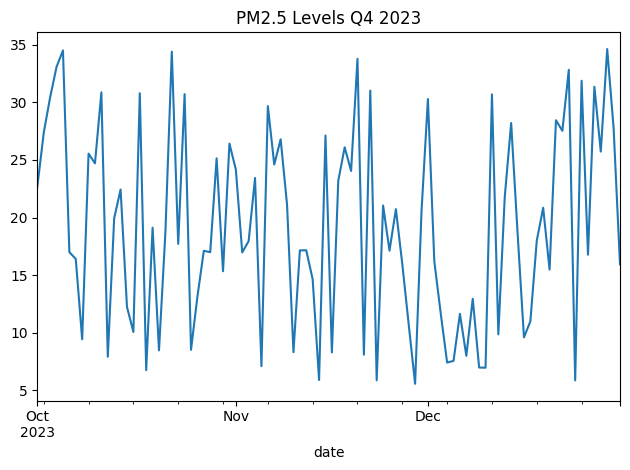

In [48]:
pm25_q4 = air_q_df.loc["2023-10":"2023-12", "pm25"]
pm25_q4.plot(title="PM2.5 Levels Q4 2023")
plt.tight_layout()
plt.show()

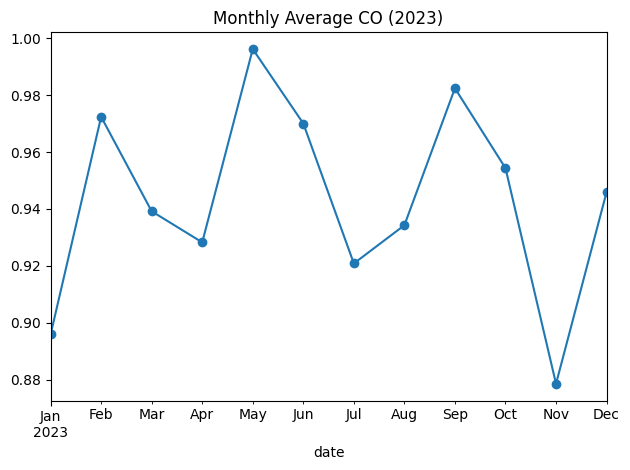

In [49]:
co_monthly = air_q_df["co"].resample("ME").mean()
co_monthly.plot(marker="o", title="Monthly Average CO (2023)")
plt.tight_layout()
plt.show()

In [50]:
oz_biz = air_q_df["ozone"].asfreq("B")
missing_holidays = oz_biz.isna().sum()
print("Missing business days in ozone data:", missing_holidays)

Missing business days in ozone data: 0


#### 🧪 Exercise: Set and Change Time Series Frequency

In [51]:
df = air_q_df.copy()

In [52]:
df_daily = df.asfreq("D")
df_daily.head()

,ozone,pm25,co
date,,,
2023-01-01,57.440675,18.758119,0.951169
2023-01-02,65.759468,26.725029,0.814028
2023-01-03,60.138169,16.970760,0.801403
2023-01-04,57.244159,32.121332,0.686995
2023-01-05,51.182740,25.700751,0.945567


In [53]:
df_hourly = df_daily.asfreq("h")
df_hourly.ffill(inplace=True)
df_hourly.head()

,ozone,pm25,co
date,,,
2023-01-01 00:00:00,57.440675,18.758119,0.951169
2023-01-01 01:00:00,57.440675,18.758119,0.951169
2023-01-01 02:00:00,57.440675,18.758119,0.951169
2023-01-01 03:00:00,57.440675,18.758119,0.951169
2023-01-01 04:00:00,57.440675,18.758119,0.951169


In [54]:
df_monthly = df_daily.resample("ME").mean()
df_monthly.head()

,ozone,pm25,co
date,,,
2023-01-31,58.545428,22.383062,0.895843
2023-02-28,53.289651,16.220186,0.972425
2023-03-31,50.632349,21.438428,0.939187
2023-04-30,56.824328,20.424696,0.928257
2023-05-31,57.523502,20.519456,0.996251


In [55]:
df_biz = df_daily.asfreq("B")
print(df_biz['ozone'].isnull().sum())
df_biz.head()

0


,ozone,pm25,co
date,,,
2023-01-02,65.759468,26.725029,0.814028
2023-01-03,60.138169,16.970760,0.801403
2023-01-04,57.244159,32.121332,0.686995
2023-01-05,51.182740,25.700751,0.945567
2023-01-06,62.294706,25.988662,1.149914


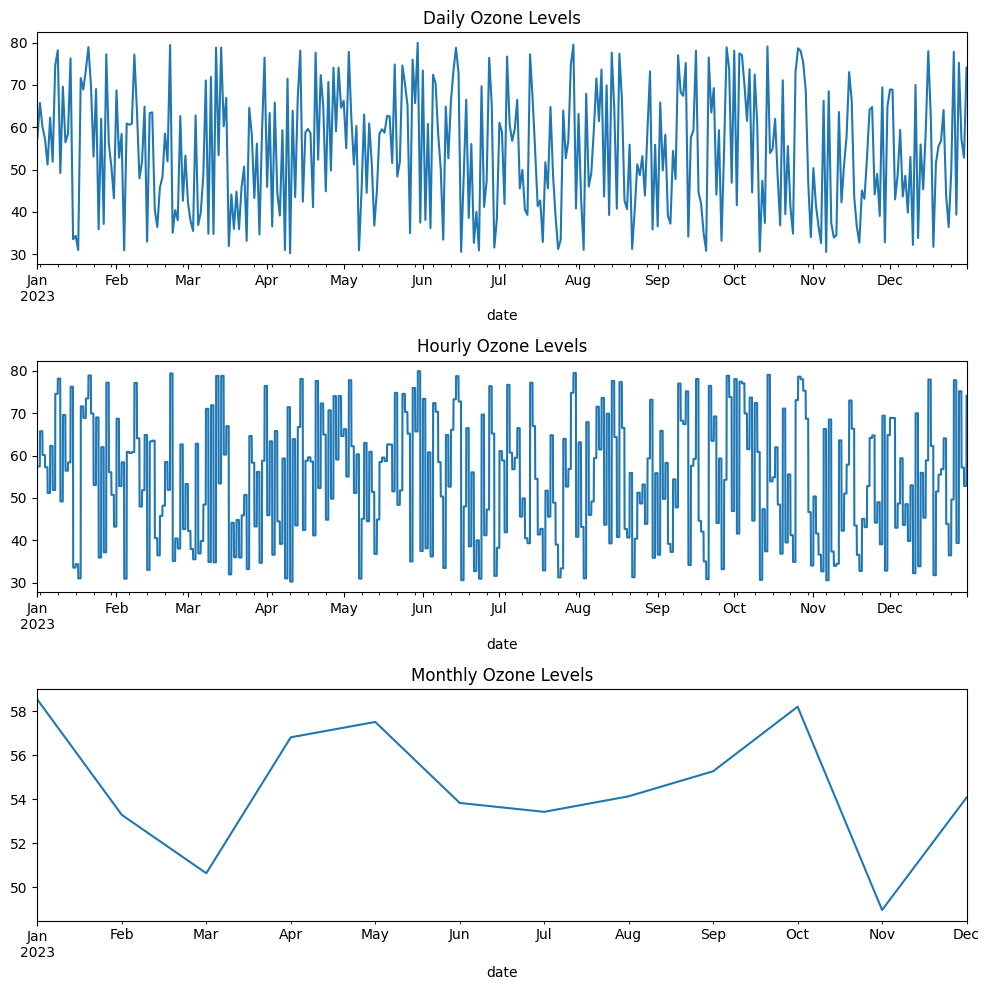

In [56]:
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(10, 10), sharex=False)
df_daily['ozone'].plot(ax=axes[0], title='Daily Ozone Levels')
df_hourly["ozone"].plot(ax=axes[1], title="Hourly Ozone Levels")
df_monthly["ozone"].plot(ax=axes[2], title="Monthly Ozone Levels")
plt.tight_layout()
plt.show()

# L3: Lags, Changes, and Returns for Stock Price Series

Shifting data

In [57]:
# Original series
price = goog["close_price"]

# 1-day lag (yesterday's price aligned to today)
goog["lag_1d"]  = price.shift(1)

# 1-day lead (tomorrow's price aligned to today)
goog["lead_1d"] = price.shift(-1)

goog[["close_price", "lag_1d", "lead_1d"]].head(3)

,close_price,lag_1d,lead_1d
date,,,
2020-01-01,1515.651425,NaN,1512.218041
2020-01-02,1512.218041,1515.651425,1532.563075
2020-01-03,1532.563075,1512.218041,1580.012143


In [58]:
# Change since previous trading day
goog["diff_1d"] = price.diff()          # equivalent to price - price.shift(1)

# Quick check: diff vs manual
check = (goog["diff_1d"] - (price - goog["lag_1d"])).abs().max()
print("Max diff between methods:", check)
goog[["close_price", "lag_1d", "diff_1d"]].head(4)

Max diff between methods: 0.0


,close_price,lag_1d,diff_1d
date,,,
2020-01-01,1515.651425,NaN,NaN
2020-01-02,1512.218041,1515.651425,-3.433384
2020-01-03,1532.563075,1512.218041,20.345035
2020-01-06,1580.012143,1532.563075,47.449068


Calculating `Simple Returns`

In [59]:
# Growth factor today vs yesterday
goog["factor_1d"] = price / goog["lag_1d"]

# Simple return in %
goog["ret_1d_pct"] = (goog["factor_1d"] - 1) * 100
goog[["close_price", "lag_1d", "factor_1d", "ret_1d_pct"]].head(5)

,close_price,lag_1d,factor_1d,ret_1d_pct
date,,,,
2020-01-01,1515.651425,NaN,NaN,NaN
2020-01-02,1512.218041,1515.651425,0.997735,-0.226529
2020-01-03,1532.563075,1512.218041,1.013454,1.345377
2020-01-06,1580.012143,1532.563075,1.030961,3.096060
2020-01-07,1573.402846,1580.012143,0.995817,-0.418307


In [60]:
# Using Built-in Method 
goog["ret_1d_pct_builtin"] = price.pct_change() * 100

# Sanity check — they should match (up to float rounding)
mismatch = (goog["ret_1d_pct"] - goog["ret_1d_pct_builtin"]).abs().max()
print("Max mismatch (percentage points):", mismatch)

Max mismatch (percentage points): 0.0


`Log Returns`

In [61]:
goog["ret_1d_log"] = np.log(price / goog["lag_1d"]) * 100
goog[["ret_1d_pct", "ret_1d_log"]].head(5)

,ret_1d_pct,ret_1d_log
date,,
2020-01-01,NaN,NaN
2020-01-02,-0.226529,-0.226786
2020-01-03,1.345377,1.336407
2020-01-06,3.096060,3.049099
2020-01-07,-0.418307,-0.419184


`Multi-Period Return`

In [62]:
# 5-day lag and 5-day simple return (%)
goog["lag_5d"]      = price.shift(5)
goog["ret_5d_pct"]  = (price / goog["lag_5d"] - 1) * 100

# Built-in: pct_change over 5 periods
goog["ret_5d_pct_builtin"] = price.pct_change(periods=5) * 100

# Check
print((goog["ret_5d_pct"] - goog["ret_5d_pct_builtin"]).abs().max())
goog.head(10)

0.0


,close_price,lag_1d,lead_1d,diff_1d,factor_1d,ret_1d_pct,ret_1d_pct_builtin,ret_1d_log,lag_5d,ret_5d_pct,ret_5d_pct_builtin
date,,,,,,,,,,,
2020-01-01,1515.651425,NaN,1512.218041,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-02,1512.218041,1515.651425,1532.563075,-3.433384,0.997735,-0.226529,-0.226529,-0.226786,NaN,NaN,NaN
2020-01-03,1532.563075,1512.218041,1580.012143,20.345035,1.013454,1.345377,1.345377,1.336407,NaN,NaN,NaN
2020-01-06,1580.012143,1532.563075,1573.402846,47.449068,1.030961,3.096060,3.096060,3.049099,NaN,NaN,NaN
2020-01-07,1573.402846,1580.012143,1566.821712,-6.609297,0.995817,-0.418307,-0.418307,-0.419184,NaN,NaN,NaN
2020-01-08,1566.821712,1573.402846,1617.092022,-6.581134,0.995817,-0.418274,-0.418274,-0.419151,1515.651425,3.376125,3.376125
2020-01-09,1617.092022,1566.821712,1642.720819,50.270309,1.032084,3.208426,3.208426,3.158031,1512.218041,6.935110,6.935110
2020-01-10,1642.720819,1617.092022,1628.117873,25.628798,1.015849,1.584869,1.584869,1.572442,1532.563075,7.187811,7.187811
2020-01-13,1628.117873,1642.720819,1646.598966,-14.602947,0.991111,-0.888949,-0.888949,-0.892923,1580.012143,3.044643,3.044643


In [63]:
# Normalize price to 100 at the first valid point
goog["price_index_100"] = price / price.iloc[0] * 100

# Or cumulate simple daily returns (as factors)
goog["cum_growth_factor"] = (1 + price.pct_change()).cumprod()
goog[["price_index_100", "cum_growth_factor"]].head(10)


,price_index_100,cum_growth_factor
date,,
2020-01-01,100.000000,NaN
2020-01-02,99.773471,0.997735
2020-01-03,101.115801,1.011158
2020-01-06,104.246406,1.042464
2020-01-07,103.810337,1.038103
2020-01-08,103.376125,1.033761
2020-01-09,106.692871,1.066929
2020-01-10,108.383814,1.083838
2020-01-13,107.420337,1.074203


Graph of `Price v/s Daily Return`

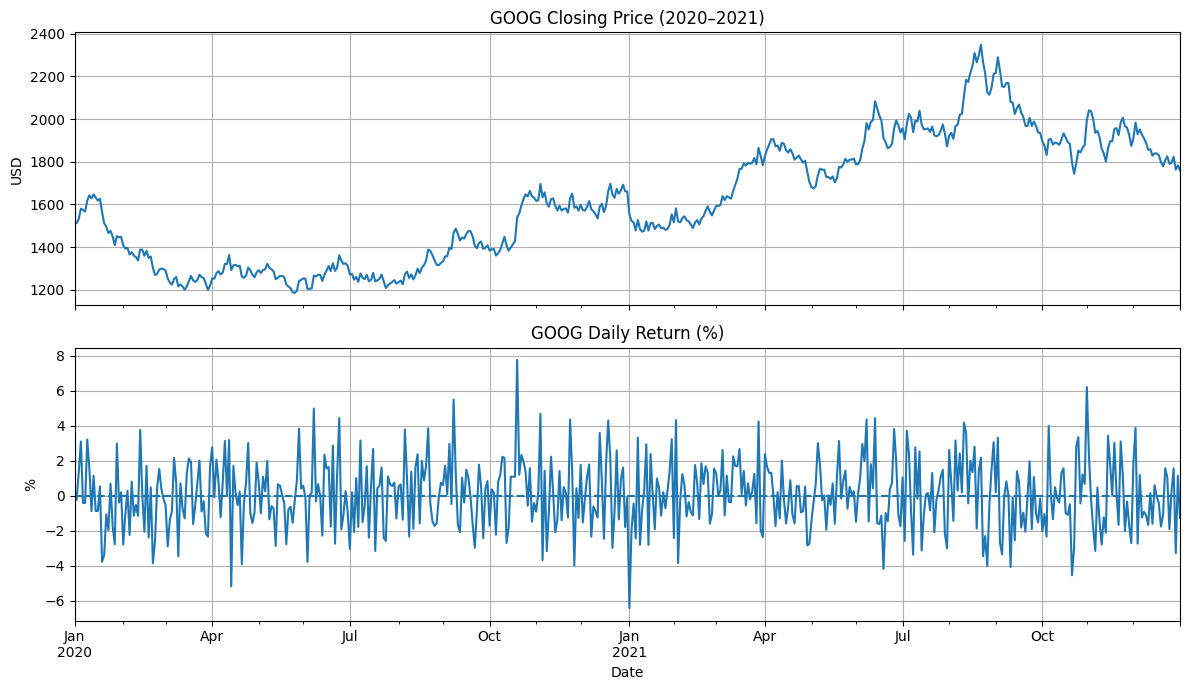

In [64]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

price.plot(ax=axes[0], title="GOOG Closing Price (2020–2021)")
axes[0].set_ylabel("USD"); axes[0].grid(True)

goog["ret_1d_pct"].plot(ax=axes[1], title="GOOG Daily Return (%)")
axes[1].axhline(0, ls="--")
axes[1].set_ylabel("%"); axes[1].set_xlabel("Date"); axes[1].grid(True)

plt.tight_layout(); plt.show()

In [65]:
returns_clean = goog["ret_1d_pct"].dropna()

#### 🧪 Hands-On Exercise: Lags, Changes, & Returns for Stock Price Series

In [66]:
price = goog['close_price']
goog['lag_1d'] = price.shift(1)
goog['lead_1d'] = price.shift(-1)
display(goog[['close_price','lag_1d','lead_1d']].head(5))
print('NaNs introduced by lag/lead:')
print(goog[['lag_1d','lead_1d']].isna().sum())

,close_price,lag_1d,lead_1d
date,,,
2020-01-01,1515.651425,NaN,1512.218041
2020-01-02,1512.218041,1515.651425,1532.563075
2020-01-03,1532.563075,1512.218041,1580.012143
2020-01-06,1580.012143,1532.563075,1573.402846
2020-01-07,1573.402846,1580.012143,1566.821712


NaNs introduced by lag/lead:
lag_1d     1
lead_1d    1
dtype: int64


In [67]:
goog['diff_1d'] = price.diff()
max_diff = (goog['diff_1d'] - (price - goog['lag_1d'])).abs().max()
print('Max diff between diff() and manual (should be ~0):', float(max_diff))
display(goog[['close_price','lag_1d','diff_1d']].head(6))

Max diff between diff() and manual (should be ~0): 0.0


,close_price,lag_1d,diff_1d
date,,,
2020-01-01,1515.651425,NaN,NaN
2020-01-02,1512.218041,1515.651425,-3.433384
2020-01-03,1532.563075,1512.218041,20.345035
2020-01-06,1580.012143,1532.563075,47.449068
2020-01-07,1573.402846,1580.012143,-6.609297
2020-01-08,1566.821712,1573.402846,-6.581134


Since we don't have anything to compare it to, first values are usually NaNs.

In [68]:
goog['factor_1d'] = price / goog['lag_1d']
goog['ret_1d_pct'] = (goog['factor_1d'] - 1) * 100
goog['ret_1d_pct_builtin'] = price.pct_change() * 100
cmp = (goog['ret_1d_pct'] - goog['ret_1d_pct_builtin']).dropna()
print('Max mismatch (percentage points):', float(cmp.abs().max()))
display(goog[['ret_1d_pct','ret_1d_pct_builtin']].head(6))

goog['ret_1d_log'] = np.log(price / goog['lag_1d'])
display(goog[['ret_1d_pct','ret_1d_log']].head(6))

Max mismatch (percentage points): 0.0


,ret_1d_pct,ret_1d_pct_builtin
date,,
2020-01-01,NaN,NaN
2020-01-02,-0.226529,-0.226529
2020-01-03,1.345377,1.345377
2020-01-06,3.096060,3.096060
2020-01-07,-0.418307,-0.418307
2020-01-08,-0.418274,-0.418274


,ret_1d_pct,ret_1d_log
date,,
2020-01-01,NaN,NaN
2020-01-02,-0.226529,-0.002268
2020-01-03,1.345377,0.013364
2020-01-06,3.096060,0.030491
2020-01-07,-0.418307,-0.004192
2020-01-08,-0.418274,-0.004192


In [69]:
goog['lag_5d'] = price.shift(5)
goog['ret_5d_pct'] = (price / goog['lag_5d'] - 1) * 100
goog['ret_5d_pct_builtin'] = price.pct_change(periods=5) * 100
cmp5 = (goog['ret_5d_pct'] - goog['ret_5d_pct_builtin']).dropna()
print('Max mismatch 5-day (percentage points):', float(cmp5.abs().max()))
display(goog[['lag_5d','ret_5d_pct','ret_5d_pct_builtin']].head(10))

Max mismatch 5-day (percentage points): 0.0


,lag_5d,ret_5d_pct,ret_5d_pct_builtin
date,,,
2020-01-01,NaN,NaN,NaN
2020-01-02,NaN,NaN,NaN
2020-01-03,NaN,NaN,NaN
2020-01-06,NaN,NaN,NaN
2020-01-07,NaN,NaN,NaN
2020-01-08,1515.651425,3.376125,3.376125
2020-01-09,1512.218041,6.935110,6.935110
2020-01-10,1532.563075,7.187811,7.187811
2020-01-13,1580.012143,3.044643,3.044643


In [70]:
returns_clean = goog['ret_1d_pct'].dropna()
summary = returns_clean.describe()
print(summary)
ann_vol = returns_clean.std() * np.sqrt(252)
print('Approx. annualized volatility (%):', float(ann_vol))

count    522.000000
mean       0.047638
std        1.952667
min       -6.432535
25%       -1.352942
50%        0.065477
75%        1.308616
max        7.755463
Name: ret_1d_pct, dtype: float64
Approx. annualized volatility (%): 30.9976311897038


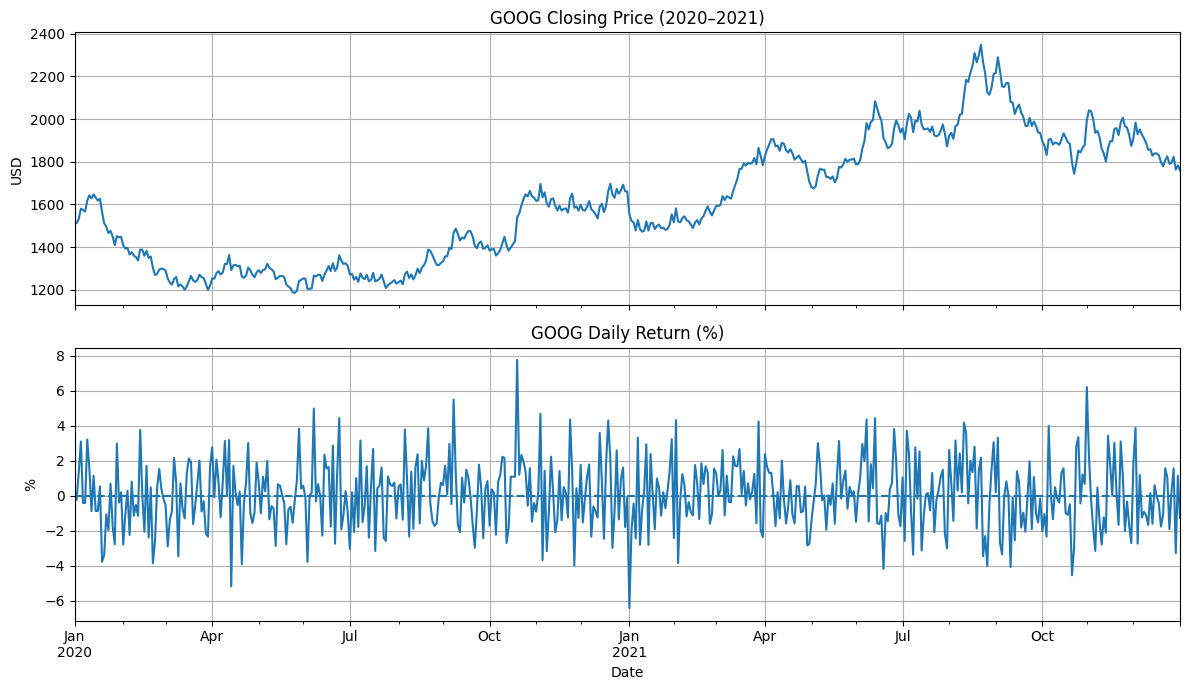

In [71]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
price.plot(ax=axes[0], title='GOOG Closing Price (2020–2021)')
axes[0].set_ylabel('USD')
axes[0].grid(True)
goog['ret_1d_pct'].plot(ax=axes[1], title='GOOG Daily Return (%)')
axes[1].axhline(0, ls='--')
axes[1].set_ylabel('%')
axes[1].set_xlabel('Date')
axes[1].grid(True)
plt.tight_layout()
plt.show()

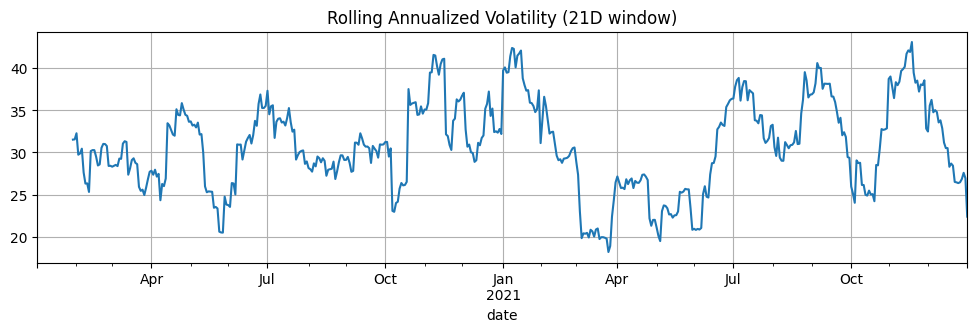

In [72]:
returns_clean = goog['ret_1d_pct'].dropna()
rolling_vol = returns_clean.rolling(21).std() * np.sqrt(252)
rolling_vol.plot(title='Rolling Annualized Volatility (21D window)', figsize=(12,3))
plt.grid(True)
plt.show()

In [73]:
tol = 1e-10
mismatch_1d = (goog['ret_1d_pct'] - goog['ret_1d_pct_builtin']).dropna().abs().max()
print('1-day returns mismatch:', float(mismatch_1d))
print('NaNs in lag_1d, lead_1d, ret_1d_pct:')
print(goog[['lag_1d','lead_1d','ret_1d_pct']].isna().sum())
assert mismatch_1d < tol, 'Manual and built-in 1-day returns differ more than tolerance'

1-day returns mismatch: 0.0
NaNs in lag_1d, lead_1d, ret_1d_pct:
lag_1d        1
lead_1d       1
ret_1d_pct    1
dtype: int64


In [74]:
goog['price_index_100'] = price / price.iloc[0] * 100
rc = goog['ret_1d_pct'].dropna()
top5 = rc.nlargest(5)
worst5 = rc.nsmallest(5)
print('Top 5 daily returns (%):')
print(top5)
print('\nWorst 5 daily returns (%):')
print(worst5)
thr = rc.std() * 3
outliers = rc[np.abs(rc) > thr]
print('\nOutliers (|ret| > 3σ):', outliers.shape[0])

Top 5 daily returns (%):
date
2020-10-20    7.755463
2021-11-01    6.207762
2020-09-08    5.490338
2020-06-08    4.976484
2020-11-04    4.679317
Name: ret_1d_pct, dtype: float64

Worst 5 daily returns (%):
date
2021-01-01   -6.432535
2020-04-14   -5.189490
2021-10-21   -4.553842
2021-06-18   -4.197791
2021-09-10   -4.084884
Name: ret_1d_pct, dtype: float64

Outliers (|ret| > 3σ): 3


# L4: Compare the Performance of Stocks, Bonds, Gold & Oil

In [75]:
df = pd.read_csv("data/assets_simulated.csv", parse_dates=["date"], index_col="date")
df.head()

,stocks,bonds,gold,oil
date,,,,
2020-01-01,988.015672,99.901858,1489.133679,57.871892
2020-01-02,999.505412,99.772249,1488.372487,58.077106
2020-01-03,1002.971545,99.913461,1481.619016,58.823458
2020-01-06,986.236137,100.114157,1485.424203,60.141394
2020-01-07,980.034995,99.769334,1471.533018,59.647521


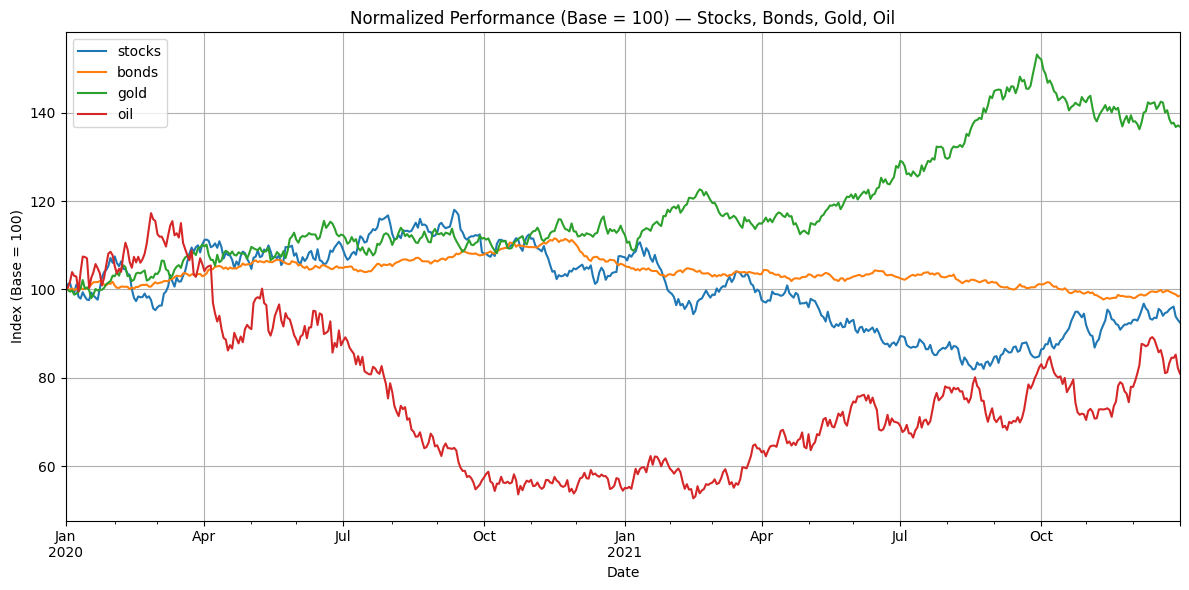

In [76]:
normalized = df / df.iloc[0] * 100
ax = normalized.plot(figsize=(12, 6), title="Normalized Performance (Base = 100) — Stocks, Bonds, Gold, Oil")
ax.set_xlabel("Date"); ax.set_ylabel("Index (Base = 100)"); ax.grid(True)
plt.tight_layout(); plt.show()

In [77]:
# Month-end 'closes'
monthly_last = df.resample("ME").last()

# Month-over-month returns (%)
monthly_returns = monthly_last.pct_change() * 100
monthly_returns.head()

,stocks,bonds,gold,oil
date,,,,
2020-01-31,NaN,NaN,NaN,NaN
2020-02-29,-10.103306,-0.111341,0.458980,7.200571
2020-03-31,15.572503,1.334084,6.342206,-8.436584
2020-04-30,-3.716807,2.638529,-1.800704,-13.612029
2020-05-31,1.484728,0.449488,4.316225,-1.817217


In [78]:
# Cumulative return over the full period (%)
cum_ret = (df.iloc[-1] / df.iloc[0] - 1) * 100
print("Cumulative return (%):")
print(cum_ret.round(2))

# Average monthly return and monthly volatility
summary = pd.DataFrame({
    "avg_monthly_return_%": monthly_returns.mean(),
    "monthly_vol_%": monthly_returns.std()
}).round(2)
summary

Cumulative return (%):
stocks    -7.49
bonds     -1.45
gold      36.83
oil      -19.06
dtype: float64


,avg_monthly_return_%,monthly_vol_%
stocks,-0.44,5.72
bonds,-0.13,1.49
gold,1.31,4.05
oil,-0.77,9.81


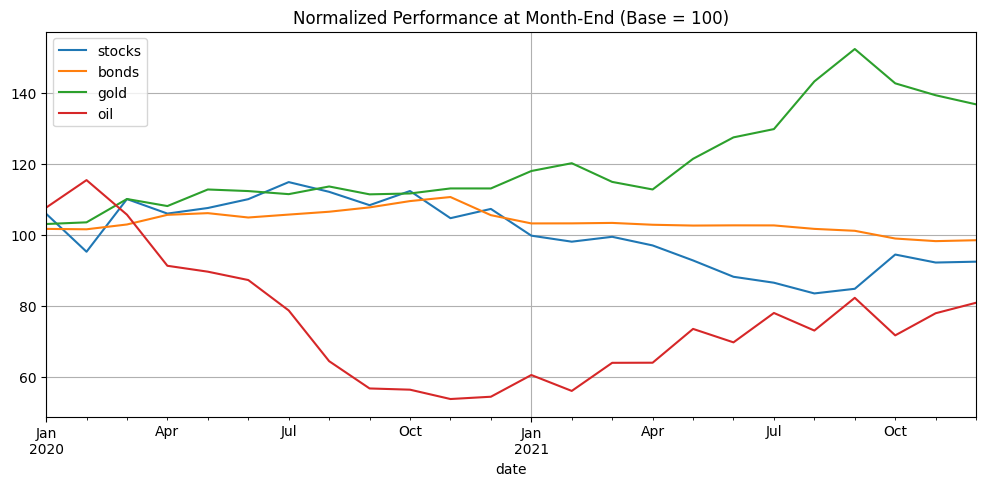

In [79]:
(normalized.resample("ME").last()).plot(
    figsize=(12, 5),
    title="Normalized Performance at Month-End (Base = 100)"
)
plt.grid(True); plt.show()

# L5: Comparing Stocks to a Benchmark

In [80]:
df = pd.read_csv("data/benchmark_stocks_simulated.csv", parse_dates=["date"], index_col="date")
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 523 entries, 2020-01-01 to 2021-12-31
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   DJIA     523 non-null    float64
 1   Stock_A  523 non-null    float64
 2   Stock_B  523 non-null    float64
 3   Stock_C  523 non-null    float64
dtypes: float64(4)
memory usage: 20.4 KB


,DJIA,Stock_A,Stock_B,Stock_C
date,,,,
2020-01-01,28546.863763,121.387060,81.585016,228.706871
2020-01-02,28401.377734,121.111576,80.194110,221.391984
2020-01-03,28416.887847,122.507099,79.304360,226.247382
2020-01-06,28553.462888,124.274453,79.087044,226.609147
2020-01-07,28304.094722,122.843393,77.335288,224.941193


Normalizing the data

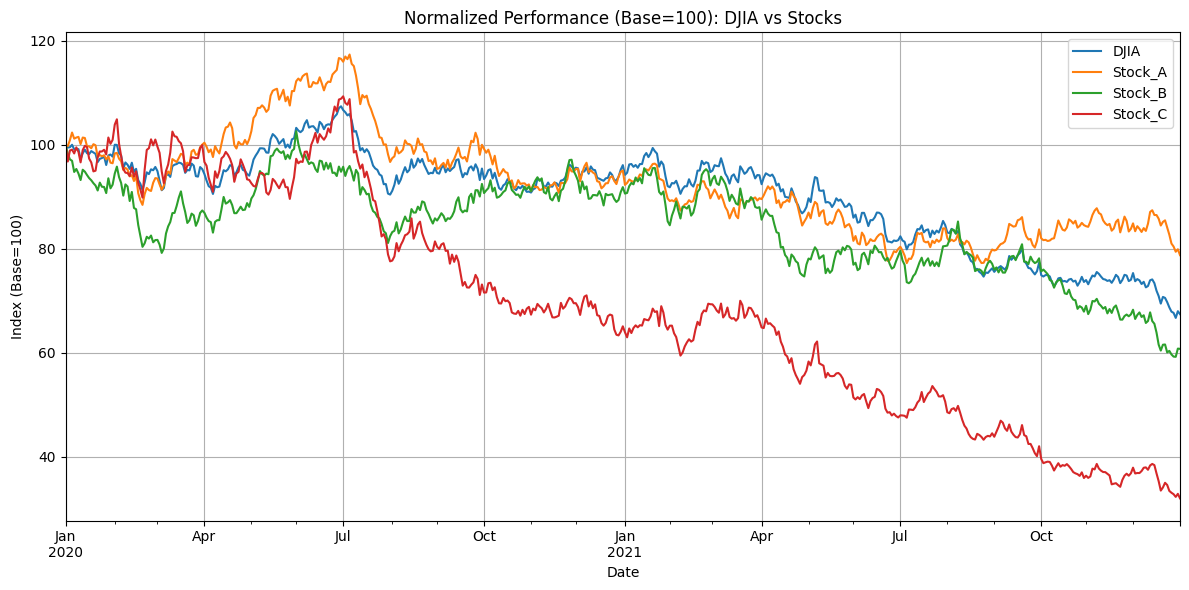

In [81]:
normalized = df / df.iloc[0] * 100

ax = normalized.plot(figsize=(12, 6),
                    title="Normalized Performance (Base=100): DJIA vs Stocks")
ax.set_xlabel("Date"); ax.set_ylabel("Index (Base=100)"); ax.grid(True)
plt.tight_layout(); plt.show()


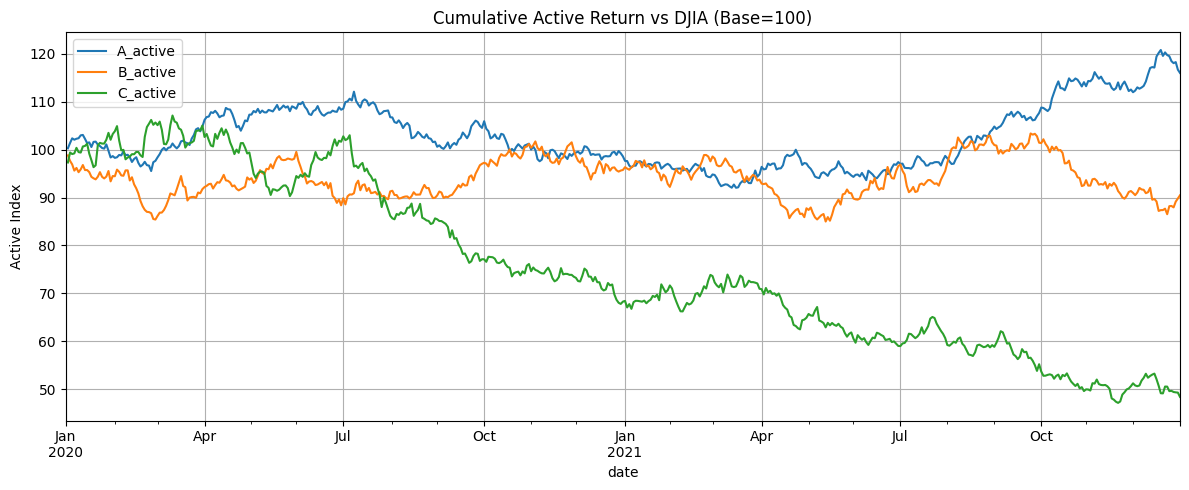

In [82]:
rets = df.pct_change() * 100

# Active return = stock return − benchmark return
active = pd.DataFrame({
    "A_active": rets["Stock_A"] - rets["DJIA"],
    "B_active": rets["Stock_B"] - rets["DJIA"],
    "C_active": rets["Stock_C"] - rets["DJIA"],
}, index=rets.index)

# Cumulative active index (Base=100)
cum_active = (1 + active/100).cumprod() * 100

cum_active.plot(figsize=(12, 5), title="Cumulative Active Return vs DJIA (Base=100)")
plt.ylabel("Active Index"); plt.grid(True); plt.tight_layout(); plt.show()


Calculating `Rolling Beta` for the market over a period/window of 60 days.

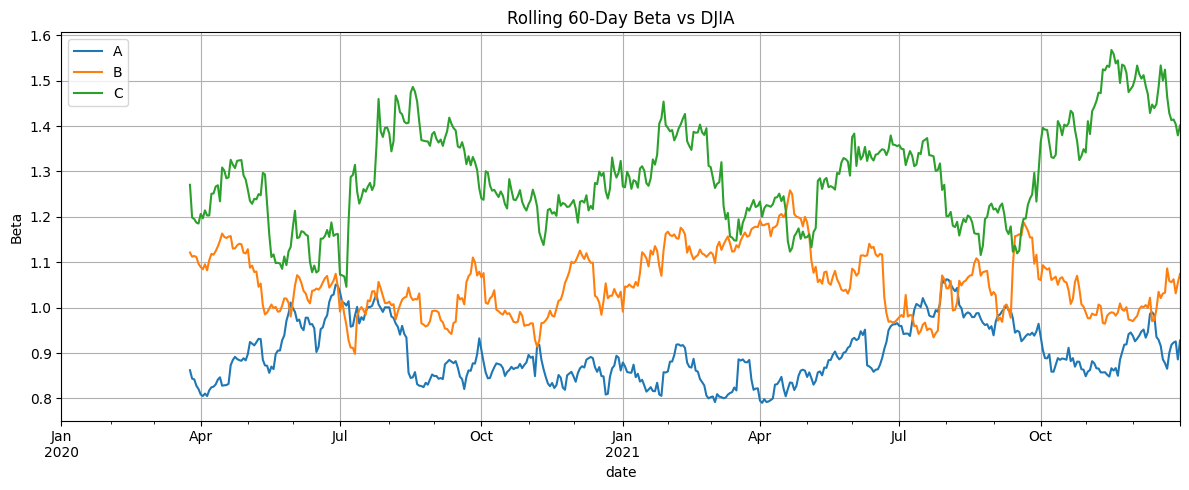

In [83]:
window = 60

# Correlations
corr_A = rets["Stock_A"].rolling(window).corr(rets["DJIA"])
corr_B = rets["Stock_B"].rolling(window).corr(rets["DJIA"])
corr_C = rets["Stock_C"].rolling(window).corr(rets["DJIA"])

# Rolling beta helper
def rolling_beta(x, y, w):
    cov = x.rolling(w).cov(y)
    var = y.rolling(w).var()
    return cov / var

beta_A = rolling_beta(rets["Stock_A"], rets["DJIA"], window)
beta_B = rolling_beta(rets["Stock_B"], rets["DJIA"], window)
beta_C = rolling_beta(rets["Stock_C"], rets["DJIA"], window)

# Plot rolling beta
pd.concat([beta_A.rename("A"), beta_B.rename("B"), beta_C.rename("C")], axis=1)\
  .plot(figsize=(12,5), title="Rolling 60-Day Beta vs DJIA")
plt.ylabel("Beta"); plt.grid(True); plt.tight_layout(); plt.show()

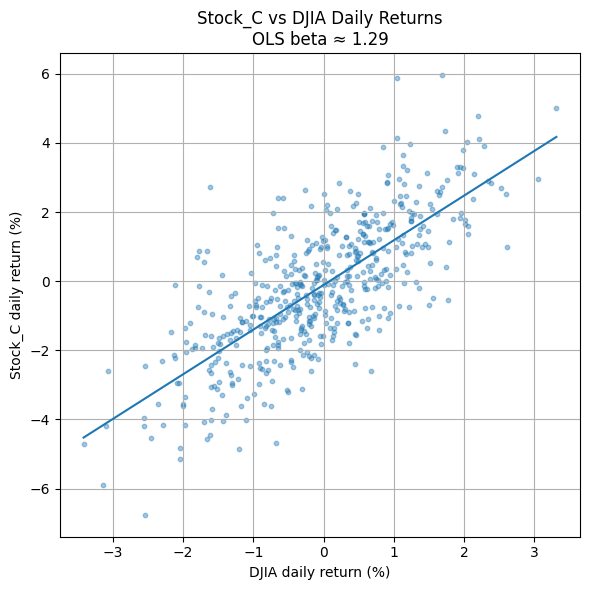

In [84]:
x = rets["DJIA"].dropna()
y = rets["Stock_C"].loc[x.index]

# OLS slope is the beta estimate
slope, intercept = np.polyfit(x, y, 1)

plt.figure(figsize=(6,6))
plt.scatter(x, y, s=10, alpha=0.4)
xline = np.linspace(x.min(), x.max(), 100)
plt.plot(xline, intercept + slope*xline)
plt.title(f"Stock_C vs DJIA Daily Returns\nOLS beta ≈ {slope:.2f}")
plt.xlabel("DJIA daily return (%)")
plt.ylabel("Stock_C daily return (%)")
plt.grid(True); plt.tight_layout(); plt.show()

# L6: Changing the Time Series Frequency: Resampling

In [85]:
# Daily prices for 2020–2021
df = pd.read_csv("data/assets_simulated.csv", parse_dates=["date"], index_col="date")

# Build a clean MONTHLY series (month-end close) for one asset
price_m = df["stocks"].resample("ME").last().rename("stocks_EOM")
price_m.head()

date
2020-01-31    1047.517884
2020-02-29     941.683948
2020-03-31    1088.327708
2020-04-30    1047.876668
2020-05-31    1063.434786
Freq: ME, Name: stocks_EOM, dtype: float64

 Monthly level → Weekly (forward-fill)

In [86]:
# Create Friday-anchored weekly index, fill forward the last known monthly value
stocks_w_ffill = price_m.resample("W-FRI").ffill()
stocks_w_ffill.head(8)

date
2020-01-31    1047.517884
2020-02-07    1047.517884
2020-02-14    1047.517884
2020-02-21    1047.517884
2020-02-28    1047.517884
2020-03-06     941.683948
2020-03-13     941.683948
2020-03-20     941.683948
Freq: W-FRI, Name: stocks_EOM, dtype: float64

Monthly average → Weekly (time interpolation)

In [87]:
stocks_w_interp = price_m.resample("W-FRI").interpolate(method="time")
stocks_w_interp.head(8)

date
2020-01-31    1047.517884
2020-02-07    1050.903856
2020-02-14    1054.289828
2020-02-21    1057.675800
2020-02-28    1061.061772
2020-03-06    1064.447744
2020-03-13    1067.833716
2020-03-20    1071.219689
Freq: W-FRI, Name: stocks_EOM, dtype: float64

Monthly total → Weekly (rate → sum)

In [88]:
# Example monthly totals (pretend our monthly series are totals)
monthly_total = price_m.copy()  # substitute your monthly totals here

# 1) Convert monthly totals to a *daily* average rate
days_in_month = monthly_total.index.days_in_month
daily_rate = (monthly_total / days_in_month).resample("D").ffill()

# 2) Sum daily rates into weekly totals (Sunday-anchored shown; pick your week-end)
weekly_total = daily_rate.resample("W-SUN").sum()
weekly_total.head()

date
2020-02-02    101.372698
2020-02-09    236.536296
2020-02-16    236.536296
2020-02-23    236.536296
2020-03-01    233.898218
Freq: W-SUN, dtype: float64

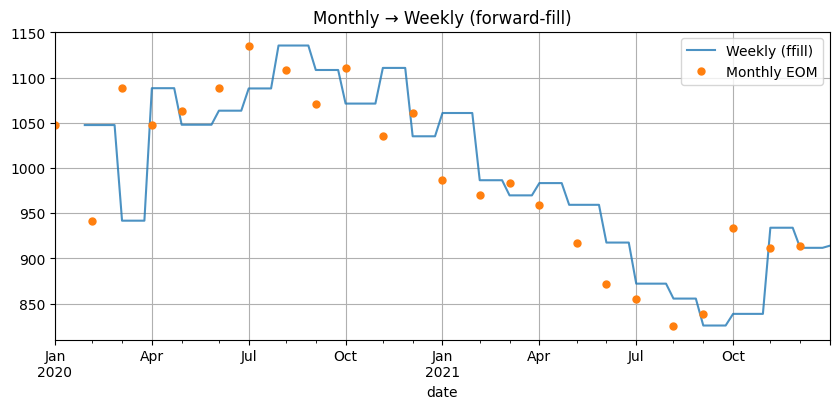

In [89]:
ax = stocks_w_ffill.plot(figsize=(10,4), label="Weekly (ffill)", alpha=0.8)
price_m.plot(style="o", ax=ax, label="Monthly EOM", markersize=5)
plt.title("Monthly → Weekly (forward-fill)"); plt.grid(True); plt.legend(); plt.show()


#### 🧪 Practice (mini-exercise)

In [90]:
df = pd.read_csv('data/assets_simulated.csv', parse_dates=['date'], index_col='date')

stocks_EOM = df['stocks'].resample('ME').last().rename('stocks_EOM')
gold_EOM   = df['gold'].resample('ME').last().rename('gold_EOM')
oil_EOM    = df['oil'].resample('ME').last().rename('oil_EOM')

stocks_EOM.head()

date
2020-01-31    1047.517884
2020-02-29     941.683948
2020-03-31    1088.327708
2020-04-30    1047.876668
2020-05-31    1063.434786
Freq: ME, Name: stocks_EOM, dtype: float64

In [91]:
stocks_W = stocks_EOM.resample('W-FRI').ffill().rename('stocks_W')

gold_W = gold_EOM.resample('W-FRI').interpolate(method='time').rename('gold_W')

monthly_total = oil_EOM.copy()

days_in_month = monthly_total.index.days_in_month
daily_rate = (monthly_total / days_in_month).resample('D').ffill()
oil_W = daily_rate.resample('W-FRI').sum().rename('oil_W')

stocks_W.head(), gold_W.head(), oil_W.head()

(date
 2020-01-31    1047.517884
 2020-02-07    1047.517884
 2020-02-14    1047.517884
 2020-02-21    1047.517884
 2020-02-28    1047.517884
 Freq: W-FRI, Name: stocks_W, dtype: float64,
 date
 2020-01-31    1535.620912
 2020-02-07    1540.441078
 2020-02-14    1545.261244
 2020-02-21    1550.081411
 2020-02-28    1554.901577
 Freq: W-FRI, Name: gold_W, dtype: float64,
 date
 2020-01-31     2.011224
 2020-02-07    14.078567
 2020-02-14    14.078567
 2020-02-21    14.078567
 2020-02-28    14.078567
 Freq: W-FRI, Name: oil_W, dtype: float64)

In [92]:
last_weekly_in_month = stocks_W.resample('ME').last()
level_check = (last_weekly_in_month - stocks_EOM).abs().max()
print('Max abs diff (stocks: last weekly in month vs EOM):', float(level_check))


oil_monthly_from_weekly = oil_W.resample('ME').sum()
total_check = (oil_monthly_from_weekly - monthly_total).abs().max()
print('Max abs diff (oil: monthly total vs sum of weekly totals):', float(total_check))

Max abs diff (stocks: last weekly in month vs EOM): 146.64376026146135
Max abs diff (oil: monthly total vs sum of weekly totals): 60.33671402716698


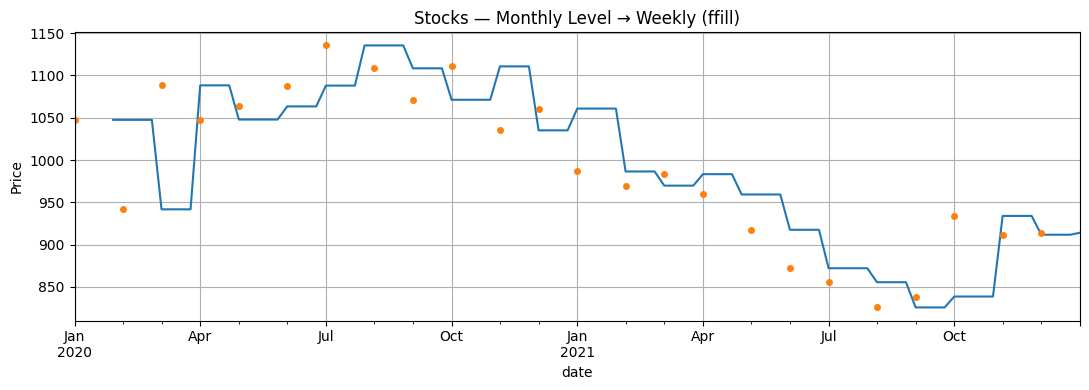

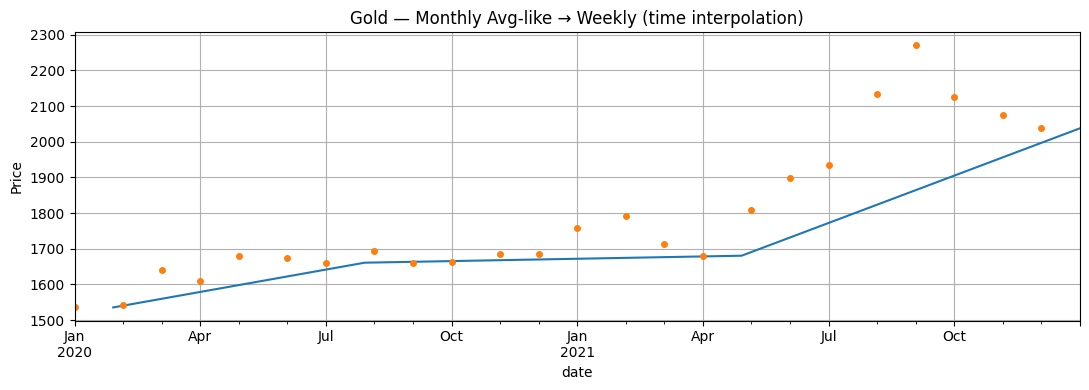

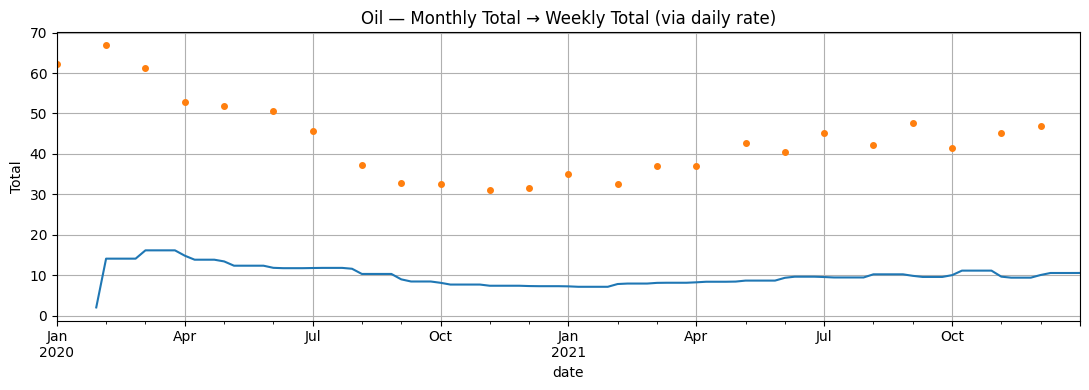

In [93]:
# Stocks
fig, ax = plt.subplots(figsize=(11,4))
stocks_W.plot(ax=ax, title='Stocks — Monthly Level → Weekly (ffill)')
stocks_EOM.plot(ax=ax, style='o', markersize=4)
ax.set_ylabel('Price'); ax.grid(True)
plt.tight_layout(); plt.show()

# Gold
fig, ax = plt.subplots(figsize=(11,4))
gold_W.plot(ax=ax, title='Gold — Monthly Avg-like → Weekly (time interpolation)')
gold_EOM.plot(ax=ax, style='o', markersize=4)
ax.set_ylabel('Price'); ax.grid(True)
plt.tight_layout(); plt.show()

# Oil
fig, ax = plt.subplots(figsize=(11,4))
oil_W.plot(ax=ax, title='Oil — Monthly Total → Weekly Total (via daily rate)')
oil_EOM.plot(ax=ax, style='o', markersize=4)
ax.set_ylabel('Total'); ax.grid(True)
plt.tight_layout(); plt.show()

#### 🧪 Exercise: Create Weekly from Monthly Unemployment Data

In [94]:
df = pd.read_csv('data/unemployment_monthly_20y.csv',
                parse_dates=['date'])
df.set_index('date', inplace=True)

df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 240 entries, 2005-09-01 to 2025-08-01
Data columns (total 1 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   unemployment_rate  240 non-null    float64
dtypes: float64(1)
memory usage: 3.8 KB


,unemployment_rate
date,
2005-09-01,5.17
2005-10-01,5.39
2005-11-01,5.27
2005-12-01,5.02
2006-01-01,5.10


In [95]:
monthly = df.asfreq('MS')
print('Freq =', monthly.index.freq)

Freq = <MonthBegin>


In [96]:
# A) Forward-fill
weekly_ffill = monthly.resample('W-FRI').ffill()

# B) Time interpolation to week end
weekly_interp = monthly.resample('W-FRI').interpolate(method='time')

# C) Daily interpolation to week mean
daily_interp = monthly.resample('D').interpolate(method='time')
weekly_mean = daily_interp.resample('W-FRI').mean()

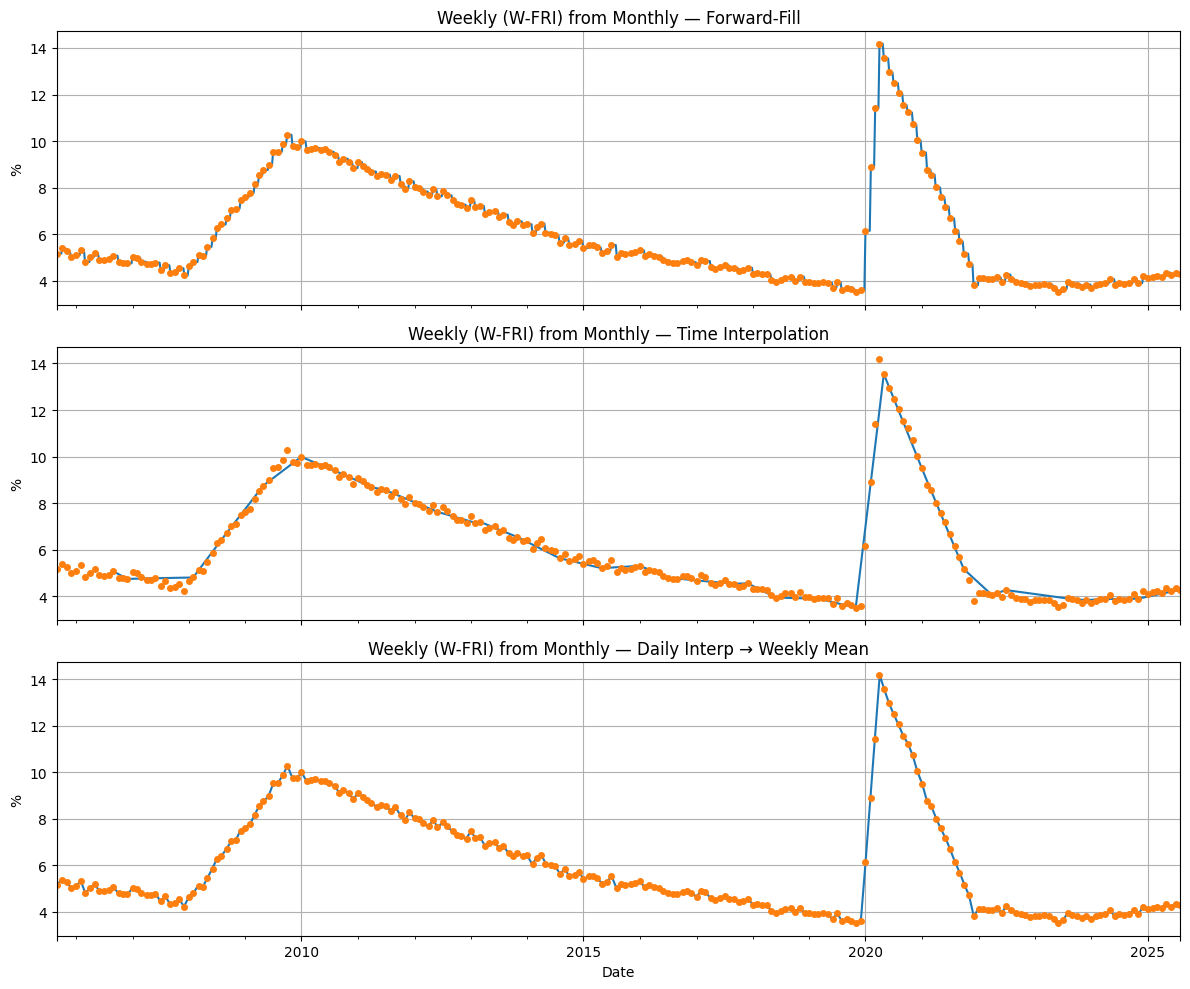

In [97]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

# A: Forward-fill
weekly_ffill['unemployment_rate'].plot(ax=axes[0], title='Weekly (W-FRI) from Monthly — Forward-Fill')
monthly['unemployment_rate'].plot(ax=axes[0], style='o', markersize=4)
axes[0].set_ylabel('%'); axes[0].grid(True)

# B: Interpolate (time)
weekly_interp['unemployment_rate'].plot(ax=axes[1], title='Weekly (W-FRI) from Monthly — Time Interpolation')
monthly['unemployment_rate'].plot(ax=axes[1], style='o', markersize=4)
axes[1].set_ylabel('%'); axes[1].grid(True)

# C: Daily interpolate → weekly mean
weekly_mean['unemployment_rate'].plot(ax=axes[2], title='Weekly (W-FRI) from Monthly — Daily Interp → Weekly Mean')
monthly['unemployment_rate'].plot(ax=axes[2], style='o', markersize=4)
axes[2].set_ylabel('%'); axes[2].set_xlabel('Date'); axes[2].grid(True)

plt.tight_layout(); plt.show()


In [98]:
print('NaNs (ffill):', weekly_ffill.isna().sum().sum())
print('NaNs (interp):', weekly_interp.isna().sum().sum())
print('NaNs (daily→weekly mean):', weekly_mean.isna().sum().sum())

monthly_from_weekly = weekly_mean.resample('MS').mean()
diff = (monthly_from_weekly - monthly)['unemployment_rate'].abs()
print('Median abs diff (pp):', float(diff.median()))
print('90th pct abs diff (pp):', float(diff.quantile(0.9)))

NaNs (ffill): 0
NaNs (interp): 52
NaNs (daily→weekly mean): 0
Median abs diff (pp): 0.05718087557603635
90th pct abs diff (pp): 0.17554024577572996


Upsampling & Interpolation with .resample()

In [99]:
df = pd.read_csv("data/employment_monthly_20y.csv", parse_dates=["date"])
df.set_index("date", inplace=True)

# Ensure a proper monthly frequency (Month Start)
monthly = df.asfreq("MS")
monthly.info()
monthly.head()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 240 entries, 2005-09-01 to 2025-08-01
Freq: MS
Data columns (total 3 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   labor_force_millions  240 non-null    float64
 1   employment_millions   240 non-null    float64
 2   unemployment_rate     240 non-null    float64
dtypes: float64(3)
memory usage: 7.5 KB


,labor_force_millions,employment_millions,unemployment_rate
date,,,
2005-09-01,150.00,142.24,5.17
2005-10-01,150.23,142.14,5.39
2005-11-01,150.43,142.50,5.27
2005-12-01,150.55,142.99,5.02
2006-01-01,150.59,142.91,5.10


Interpolating weekly directly form the monthly. -> Anchored to Fridays.

In [100]:
weekly_interp = monthly["employment_millions"].resample("W-FRI").interpolate(method="time")
weekly_interp.head()

date
2005-09-02   NaN
2005-09-09   NaN
2005-09-16   NaN
2005-09-23   NaN
2005-09-30   NaN
Freq: W-FRI, Name: employment_millions, dtype: float64

Method_2: Monthly -> Daily interpolation -> Weekly mean

In [101]:
daily_curve = monthly["employment_millions"].resample("D").interpolate(method="time")
weekly_mean = daily_curve.resample("W-FRI").mean()
weekly_mean.head()

date
2005-09-02    142.238333
2005-09-09    142.223333
2005-09-16    142.200000
2005-09-23    142.176667
2005-09-30    142.153333
Freq: W-FRI, Name: employment_millions, dtype: float64

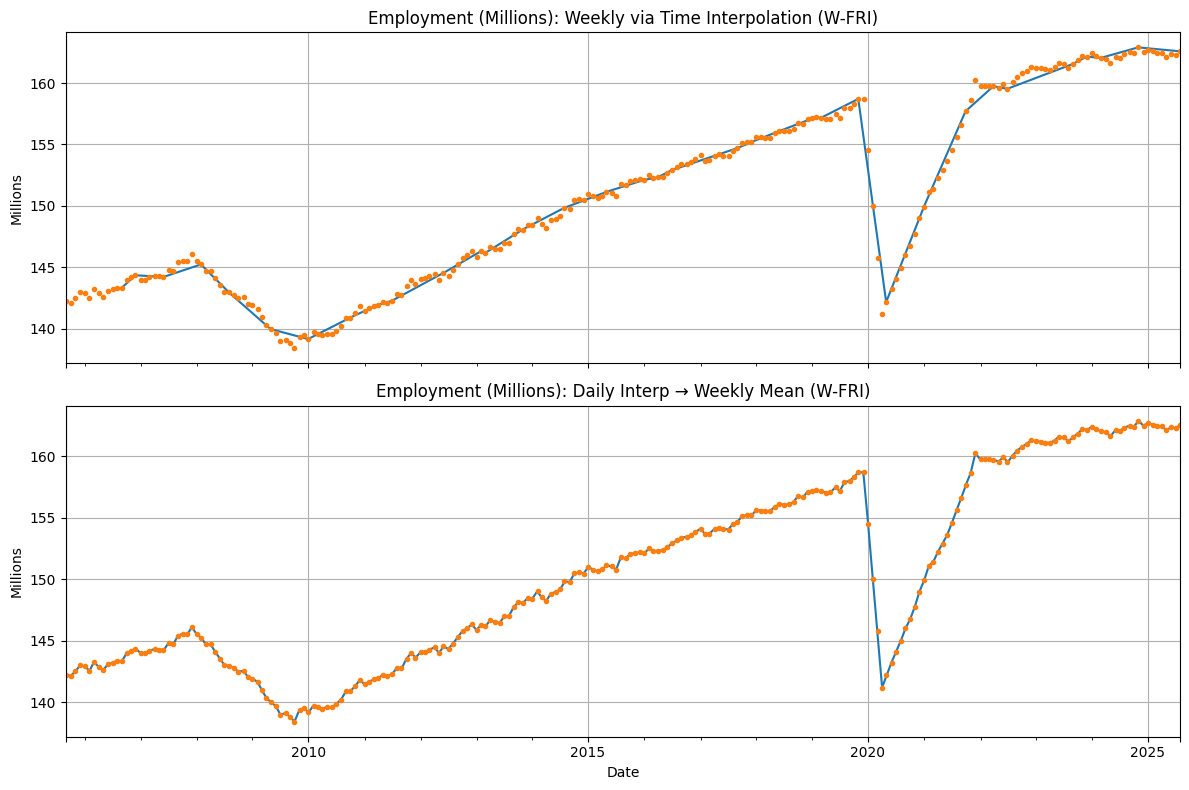

In [102]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)


# A) Weekly via time interpolation
weekly_interp.plot(ax=axes[0], title="Employment (Millions): Weekly via Time Interpolation (W-FRI)")
monthly["employment_millions"].plot(ax=axes[0], style="o", markersize=3)
axes[0].set_ylabel("Millions"); axes[0].grid(True)

# B) Daily interpolate → weekly mean
weekly_mean.plot(ax=axes[1], title="Employment (Millions): Daily Interp → Weekly Mean (W-FRI)")
monthly["employment_millions"].plot(ax=axes[1], style="o", markersize=3)
axes[1].set_ylabel("Millions"); axes[1].set_xlabel("Date"); axes[1].grid(True)

plt.tight_layout(); plt.show()

In [103]:
print("NaNs (weekly_interp):", weekly_interp.isna().sum())
print("NaNs (weekly_mean):", weekly_mean.isna().sum())

NaNs (weekly_interp): 52
NaNs (weekly_mean): 0


In [104]:
monthly_from_weekly = weekly_mean.resample("MS").mean()
diff = (monthly_from_weekly - monthly["employment_millions"]).abs()
print("Median abs diff (millions):", float(diff.median()))
print("90th pct abs diff (millions):", float(diff.quantile(0.9)))

Median abs diff (millions): 0.10418836405528964
90th pct abs diff (millions): 0.3024665898617456


#### 🧪 Exercise: Interpolate Debt/GDP and Compare to Unemployment

In [105]:
debt = pd.read_csv("data/debt_gdp_quarterly_20y.csv", parse_dates=["date"]).set_index("date")
unemp = pd.read_csv("data/unemployment_monthly_20y.csv", parse_dates=["date"]).set_index("date")

debt.info(); print()
unemp.info()
debt.head(), unemp.head()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 80 entries, 2005-07-01 to 2025-04-01
Data columns (total 1 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   debt_gdp_pct  80 non-null     float64
dtypes: float64(1)
memory usage: 1.2 KB

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 240 entries, 2005-09-01 to 2025-08-01
Data columns (total 1 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   unemployment_rate  240 non-null    float64
dtypes: float64(1)
memory usage: 3.8 KB


(            debt_gdp_pct
 date                    
 2005-07-01         59.41
 2005-10-01         61.36
 2006-01-01         62.53
 2006-04-01         63.50
 2006-07-01         62.07,
             unemployment_rate
 date                         
 2005-09-01               5.17
 2005-10-01               5.39
 2005-11-01               5.27
 2005-12-01               5.02
 2006-01-01               5.10)

In [106]:
# Quarter start for Debt/GDP
debt_q = debt.asfreq("QS")

# Month start for unemployment
unemp_m = unemp.asfreq("MS")
print("Debt freq:", debt_q.index.freq, " | Unemp freq:", unemp_m.index.freq)

Debt freq: <QuarterBegin: startingMonth=1>  | Unemp freq: <MonthBegin>


In [107]:
# A. Direct monthly via time interpolation

debt_m_time = debt_q.resample("MS").interpolate(method="time")

# B. Daily interpolation → monthly mean

debt_d_daily = debt_q.resample("D").interpolate(method="time")
debt_m_mean  = debt_d_daily.resample("MS").mean()

In [108]:
combo_time = unemp_m.join(debt_m_time, how="inner")
combo_mean = unemp_m.join(debt_m_mean, how="inner")

combo_time.head(), combo_mean.head()

(            unemployment_rate  debt_gdp_pct
 date                                       
 2005-09-01               5.17     60.724130
 2005-10-01               5.39     61.360000
 2005-11-01               5.27     61.754239
 2005-12-01               5.02     62.135761
 2006-01-01               5.10     62.530000,
             unemployment_rate  debt_gdp_pct
 date                                       
 2005-09-01               5.17     61.031467
 2005-10-01               5.39     61.550761
 2005-11-01               5.27     61.938641
 2005-12-01               5.02     62.326522
 2006-01-01               5.10     62.691667)

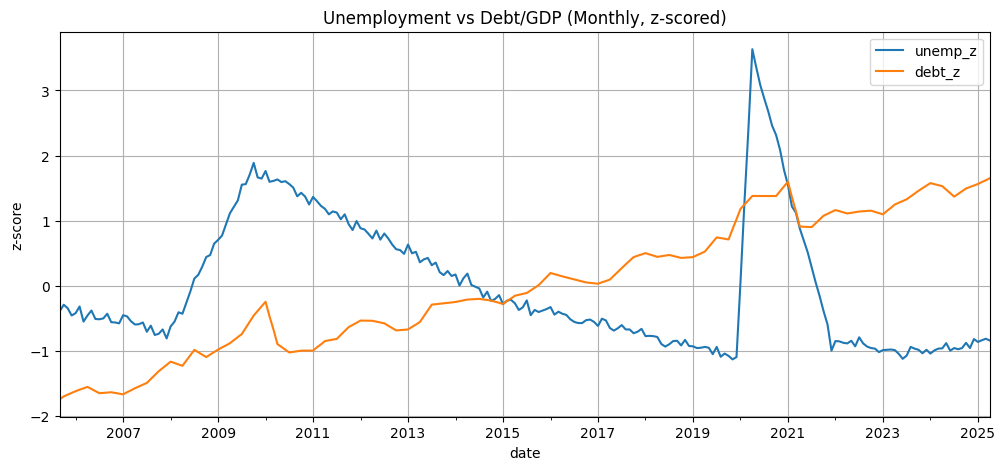

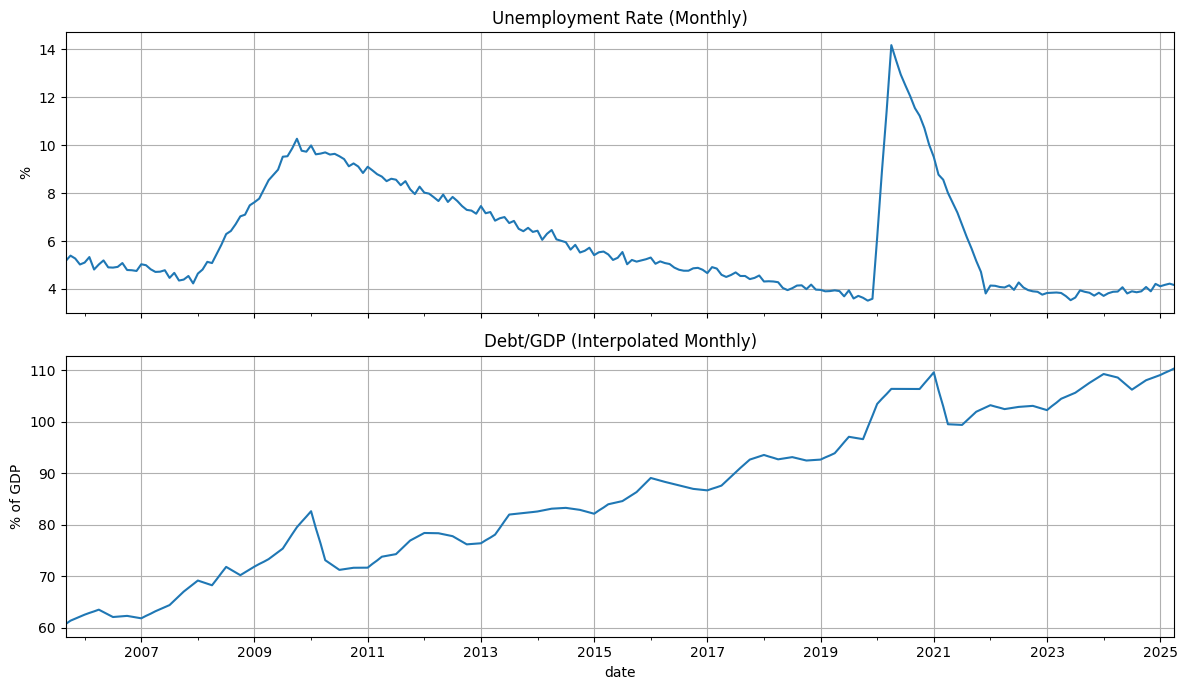

In [109]:
# Option 1 — Overlaid (z-scored) on one axis
# (Standardize both to zero-mean, unit-std so scales match.)
z = lambda s: (s - s.mean()) / s.std()

plot_df = pd.DataFrame({
    "unemp_z": z(combo_time["unemployment_rate"]),
    "debt_z" : z(combo_time["debt_gdp_pct"])
}, index=combo_time.index)

ax = plot_df.plot(figsize=(12,5), title="Unemployment vs Debt/GDP (Monthly, z-scored)")
ax.set_ylabel("z-score"); ax.grid(True)


# Option 2 — Two subplots (original scales)


fig, axes = plt.subplots(2,1, figsize=(12,7), sharex=True)
combo_time["unemployment_rate"].plot(ax=axes[0], title="Unemployment Rate (Monthly)")
axes[0].set_ylabel("%"); axes[0].grid(True)
combo_time["debt_gdp_pct"].plot(ax=axes[1], title="Debt/GDP (Interpolated Monthly)")
axes[1].set_ylabel("% of GDP"); axes[1].grid(True)
plt.tight_layout(); plt.show()


In [110]:
corr_levels = combo_time[["unemployment_rate","debt_gdp_pct"]].corr().iloc[0,1]
print("Correlation (levels):", corr_levels)

diff_corr = combo_time.diff().dropna().corr().iloc[0,1]
print("Correlation (first differences):", diff_corr)

# Example: correlation when Debt/GDP leads unemployment by 3 months
lead = 3
lag_corr = combo_time["debt_gdp_pct"].shift(lead).corr(combo_time["unemployment_rate"])
print(f"Corr( Debt/GDP lead {lead}m, Unemp ): {lag_corr}")

Correlation (levels): -0.17841539227826575
Correlation (first differences): 0.24237433984514772
Corr( Debt/GDP lead 3m, Unemp ): -0.1819925218215665


In [111]:
corr_levels_mean = combo_mean[["unemployment_rate","debt_gdp_pct"]].corr().iloc[0,1]
print("Correlation using daily→monthly mean:", corr_levels_mean)

Correlation using daily→monthly mean: -0.18210872867776534


# L7: Downsampling and Aggregation

In [112]:
goog = pd.read_csv("data/goog_simulated.csv", parse_dates=["date"], index_col="date")
price = goog["close_price"]

# A) Month-end "close" (common in markets)
m_close = price.resample("ME").last()

# B) Monthly average price (less common for returns, fine for smoothing)
m_avg = price.resample("ME").mean()

# C) OHLC in one shot (open/high/low/close)
m_ohlc = price.resample("ME").ohlc()

print(m_close.head())
print(m_ohlc.head())

date
2020-01-31    1448.515094
2020-02-29    1297.440514
2020-03-31    1219.677896
2020-04-30    1283.067523
2020-05-31    1246.506836
Freq: ME, Name: close_price, dtype: float64
                   open         high          low        close
date                                                          
2020-01-31  1515.651425  1646.598966  1409.643036  1448.515094
2020-02-29  1407.963966  1407.963966  1269.606599  1297.440514
2020-03-31  1290.275951  1290.275951  1199.584240  1219.677896
2020-04-30  1253.371254  1363.483629  1252.192832  1283.067523
2020-05-31  1292.145254  1321.783182  1185.667371  1246.506836


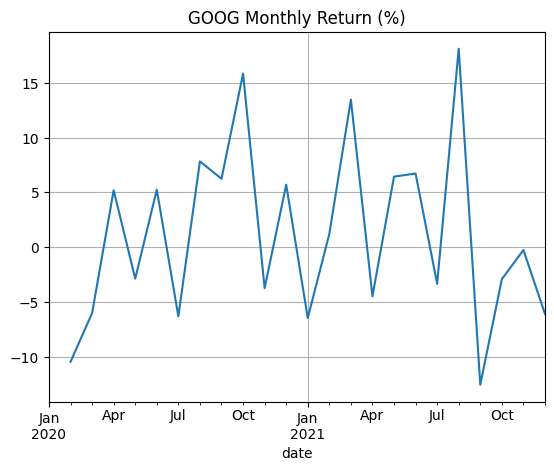

Max diff in growth factor: 8942322.257542448


In [113]:
m_ret = m_close.pct_change() * 100
m_ret.plot(title="GOOG Monthly Return (%)"); plt.grid(True); plt.show()

# Cumulative growth factors of daily returns per month ≈ 1 + monthly_return
daily_fac = (1 + price.pct_change()).resample("ME").apply(lambda s: (s.dropna()+1).prod())
check = (daily_fac - (1 + m_ret/100)).abs().max()
print("Max diff in growth factor:", float(check))

In [114]:
# Weekly mean, weeks ending Friday, intervals closed on the right
w_mean = price.resample("W-FRI", label="right", closed="right").mean()

# Weekly last (a "weekly close")
w_close = price.resample("W-FRI", label="right", closed="right").last()


In [115]:
aq = pd.read_csv("data/air_quality_trends_simulated.csv", parse_dates=["date"], index_col="date")

monthly_aq = aq.resample("ME").agg({
    "ozone": "mean",   # average daily ozone
    "pm25":  "max",    # worst monthly day
    "co":    "median"  # robust central tendency
})
monthly_aq.head()

,ozone,pm25,co
date,,,
2023-01-31,58.545428,33.774998,0.814028
2023-02-28,53.289651,34.710350,0.893725
2023-03-31,50.632349,34.760337,0.849133
2023-04-30,56.824328,34.832024,0.923890
2023-05-31,57.523502,34.033840,0.941081


In [116]:
# Month-end on business calendar
bm_close = price.resample("BME").last()   # last business day of month

# Week anchored to Friday (already shown)
w_fri = price.resample("W-FRI").last()

# Quarter-end (calendar)
q_close = price.resample("QE").last()

In [117]:
# Pre-fill short gaps *before* downsampling if appropriate
price_ff = price.asfreq("B").ffill(limit=2)      # fill ≥2-day gaps
m_close_ff = price_ff.resample("ME").last()

# Or after downsampling, if you need a continuous series
m_close_filled = m_close.ffill()

In [118]:
# Monthly volatility proxy: std of daily returns within the month
m_vol = price.pct_change().resample("ME").std() * np.sqrt(21) * 100  # % monthly vol (annualize if you want)

In [119]:
monthly_summary = pd.concat({
    "close": m_close,
    "ret_%": m_ret,
    "vol_%": m_vol
}, axis=1)
monthly_summary.head()


,close,ret_%,vol_%
date,,,
2020-01-31,1448.515094,NaN,8.886921
2020-02-29,1297.440514,-10.429617,8.385018
2020-03-31,1219.677896,-5.993540,7.811784
2020-04-30,1283.067523,5.197243,9.815226
2020-05-31,1246.506836,-2.849475,6.877270


In [120]:
dow_mean = price.groupby(price.index.day_name()).mean().sort_index()
print(dow_mean)

date
Friday       1612.681503
Monday       1616.693604
Thursday     1617.216967
Tuesday      1616.103922
Wednesday    1614.009378
Name: close_price, dtype: float64


# L8: Seeing the Month Clearly: Mean, Median & Standard Deviation

In [121]:
df = pd.read_csv("data/air_quality_trends_simulated.csv", parse_dates=["date"])
df.set_index("date", inplace=True)

# Confirm structure
df.info()
df.head()
# Optional: ensure daily frequency gaps are visible (we won't fill yet)
df = df.asfreq("D")

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 365 entries, 2023-01-01 to 2023-12-31
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   ozone   365 non-null    float64
 1   pm25    365 non-null    float64
 2   co      365 non-null    float64
dtypes: float64(3)
memory usage: 11.4 KB


In [122]:
monthly_stats = df.resample("ME").agg({
    "ozone": ["mean", "median", "std"],
    "pm25":  ["mean", "median", "std"],
    "co":    ["mean", "median", "std"]
})
monthly_stats.head()


ozone                             pm25                       \
                 mean     median        std       mean     median       std   
date                                                                          
2023-01-31  58.545428  58.402228  14.294243  22.383062  23.866953  8.430659   
2023-02-28  53.289651  53.061528  13.011553  16.220186  13.698381  9.493230   
2023-03-31  50.632349  45.899159  15.002581  21.438428  20.519256  9.203528   
2023-04-30  56.824328  59.194645  14.095023  20.424696  18.516700  9.054840   
2023-05-31  57.523502  59.543638  13.043894  20.519456  20.175992  7.344971   

                  co                      
                mean    median       std  
date                                      
2023-01-31  0.895843  0.814028  0.327075  
2023-02-28  0.972425  0.893725  0.333681  
2023-03-31  0.939187  0.849133  0.311558  
2023-04-30  0.928257  0.923890  0.323582  
2023-05-31  0.996251  0.941081  0.319338

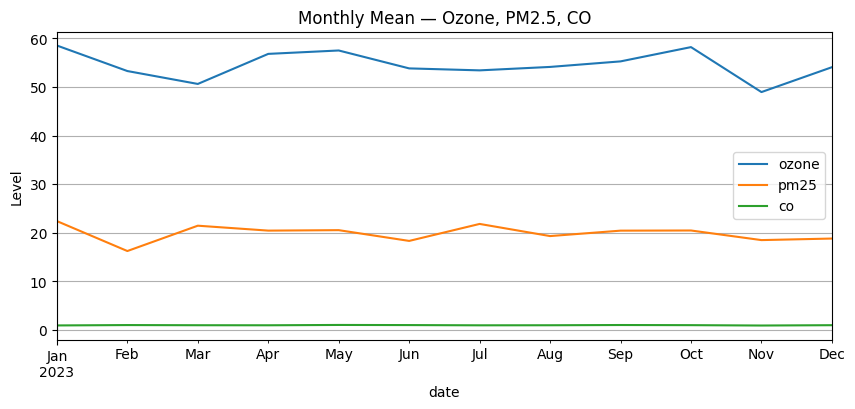

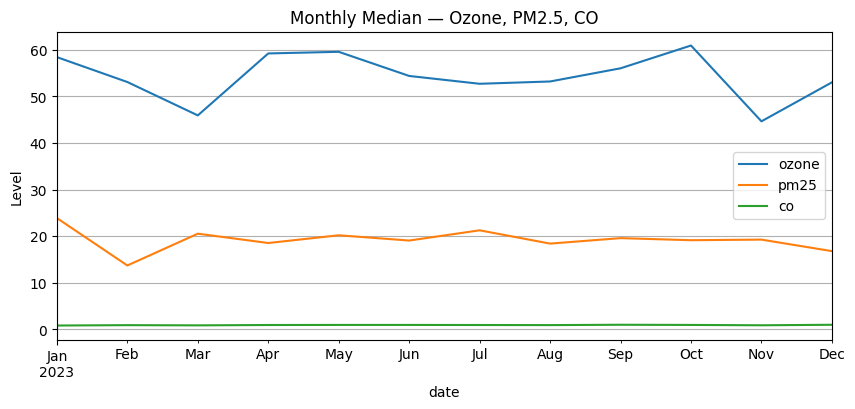

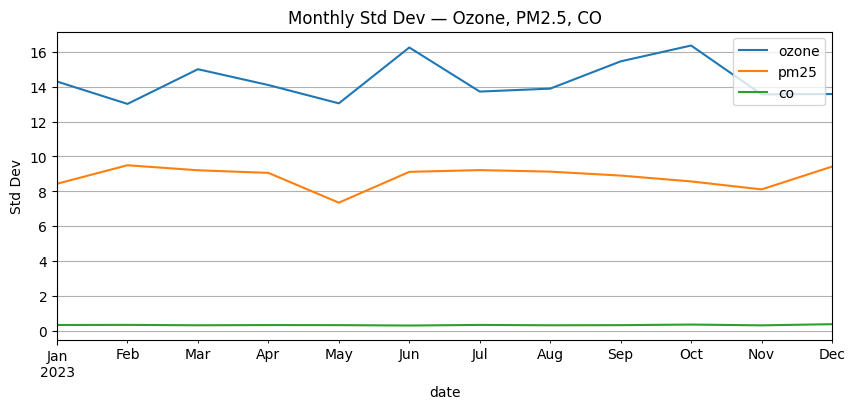

In [123]:
# Monthly mean
monthly_mean = df.resample("ME").mean(numeric_only=True)
monthly_mean.plot(title="Monthly Mean — Ozone, PM2.5, CO", figsize=(10,4))
plt.ylabel("Level"); plt.grid(True); plt.show()

# Monthly median
monthly_median = df.resample("ME").median(numeric_only=True)
monthly_median.plot(title="Monthly Median — Ozone, PM2.5, CO", figsize=(10,4))
plt.ylabel("Level"); plt.grid(True); plt.show()

# Monthly standard deviation
monthly_std = df.resample("ME").std(numeric_only=True)
monthly_std.plot(title="Monthly Std Dev — Ozone, PM2.5, CO", figsize=(10,4))
plt.ylabel("Std Dev"); plt.grid(True); plt.show()


In [124]:
mm = monthly_mean.copy()
ms = monthly_std.copy()

# Mark the month with the highest PM2.5 mean and highest PM2.5 std
pm25_max_mean_month = mm["pm25"].idxmax()
pm25_max_std_month  = ms["pm25"].idxmax()
print("Highest PM2.5 mean month:", pm25_max_mean_month.date())
print("Highest PM2.5 std month:",  pm25_max_std_month.date())


Highest PM2.5 mean month: 2023-01-31
Highest PM2.5 std month: 2023-02-28


In [125]:
df.resample("ME").count()

,ozone,pm25,co
date,,,
2023-01-31,31,31,31
2023-02-28,28,28,28
2023-03-31,31,31,31
2023-04-30,30,30,30
2023-05-31,31,31,31
2023-06-30,30,30,30
2023-07-31,31,31,31
2023-08-31,31,31,31
2023-09-30,30,30,30


In [126]:
mo = df.groupby(df.index.month).agg(["mean","median","std"])
mo

ozone                             pm25                       \
           mean     median        std       mean     median       std   
date                                                                    
1     58.545428  58.402228  14.294243  22.383062  23.866953  8.430659   
2     53.289651  53.061528  13.011553  16.220186  13.698381  9.493230   
3     50.632349  45.899159  15.002581  21.438428  20.519256  9.203528   
4     56.824328  59.194645  14.095023  20.424696  18.516700  9.054840   
5     57.523502  59.543638  13.043894  20.519456  20.175992  7.344971   
6     53.834532  54.364482  16.248663  18.303276  19.047193  9.113604   
7     53.429428  52.684842  13.719370  21.802050  21.241424  9.213754   
8     54.137654  53.178771  13.888553  19.300231  18.391832  9.125996   
9     55.277591  56.006219  15.453034  20.418219  19.565490  8.900116   
10    58.217981  60.893835  16.361679  20.450357  19.118627  8.564407   
11    48.958200  44.627937  13.558326  18.472083  19.248649  8.106675   
12    54.080392  52.992794  13.578076  18.791997  16.777064  9.415189   

            co                      
          mean    median       std  
date                                
1     0.895843  0.814028  0.327075  
2     0.972425  0.893725  0.333681  
3     0.939187  0.849133  0.311558  
4     0.928257  0.923890  0.323582  
5     0.996251  0.941081  0.319338  
6     0.970066  0.941525  0.296879  
7     0.920828  0.923148  0.331124  
8     0.934281  0.904867  0.311579  
9     0.982460  0.977407  0.318041  
10    0.954368  0.939462  0.351719  
11    0.878502  0.866814  0.306974  
12    0.945912  0.972746  0.373614

# L9: Rolling Window Functions

Rolling windows turn noisy time series into interpretable signals. -> Rolling windows are a way to compute statistics over a moving time window in a time series. -> This smooths noisy day‑to‑day fluctuations and reveals trends or volatility more clearly.


A rolling/“moving” window computes a statistic over the last N observations (row-based) or last N units of time (time-based).

In [127]:
# Air quality (daily)
aq = pd.read_csv("data/air_quality_trends_simulated.csv", parse_dates=["date"], index_col="date").asfreq("D")

# GOOG prices (business-daily)
goog = pd.read_csv("data/goog_simulated.csv", parse_dates=["date"], index_col="date")
goog = goog.asfreq("B")  # ensure business-day frequency
price = goog["close_price"]

# Multi-asset (business-daily)
assets = pd.read_csv("data/assets_simulated.csv", parse_dates=["date"], index_col="date").asfreq("B")

plt.rcParams["figure.figsize"] = (10, 4)

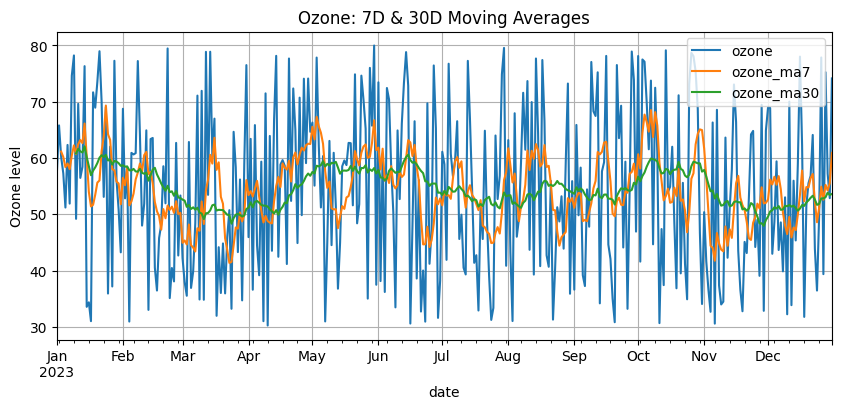

In [128]:
# Row-based windows (last N rows)
aq["ozone_ma7"]  = aq["ozone"].rolling(window=7, min_periods=3).mean()
aq["ozone_ma30"] = aq["ozone"].rolling(window=30, min_periods=10).mean()

ax = aq[["ozone", "ozone_ma7", "ozone_ma30"]].plot(title="Ozone: 7D & 30D Moving Averages")
ax.set_ylabel("Ozone level"); ax.grid(True); plt.show()


 Early windows don’t have enough rows; min_periods lets you start producing values sooner (with a warning to interpret carefully).

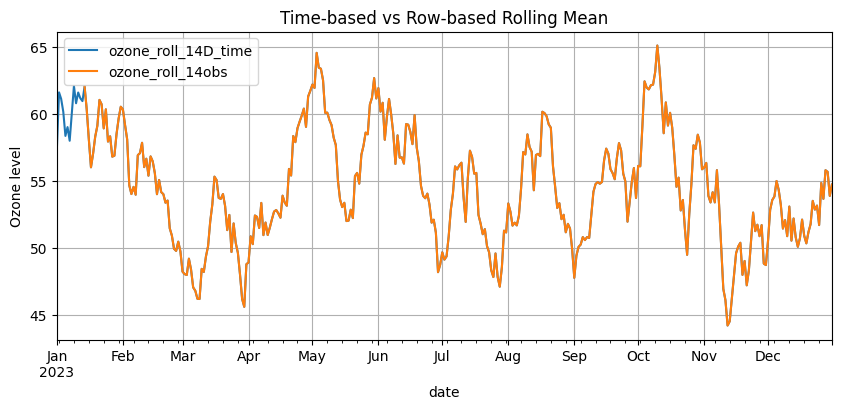

In [129]:
# Time-based: last 14 calendar days (uses timestamps, robust to gaps)
aq["ozone_roll_14D_time"] = aq["ozone"].rolling("14D").mean()

# Row-based: last 14 observations (ignores actual time span)
aq["ozone_roll_14obs"] = aq["ozone"].rolling(14).mean()

aq[["ozone_roll_14D_time","ozone_roll_14obs"]].plot(title="Time-based vs Row-based Rolling Mean")
plt.ylabel("Ozone level"); plt.grid(True); plt.show()


Use time-based windows when your index has real-world spacing (irregular sampling, missing dates). Use row-based windows when every row is equally spaced and complete.

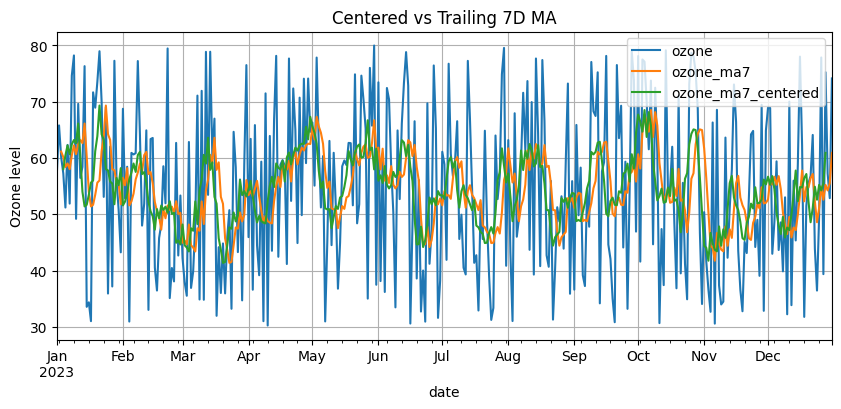

In [130]:
aq["ozone_ma7_centered"] = aq["ozone"].rolling(7, center=True).mean()
aq[["ozone","ozone_ma7","ozone_ma7_centered"]].plot(title="Centered vs Trailing 7D MA")
plt.ylabel("Ozone level"); plt.grid(True); plt.show()

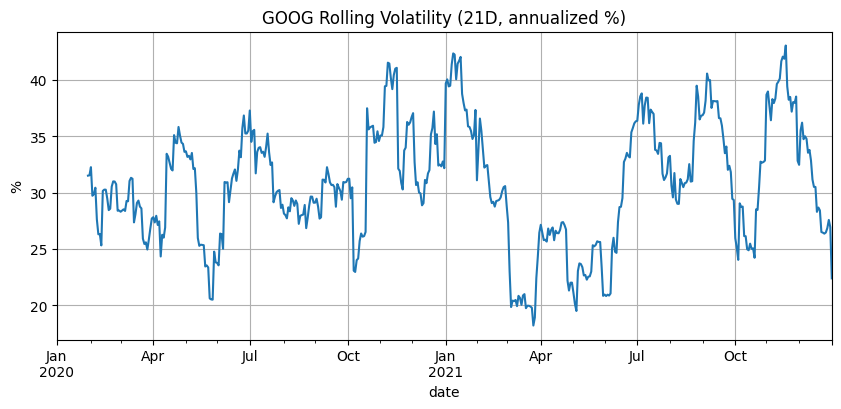

In [131]:
# Daily returns
ret = price.pct_change()

# 21 trading-day rolling volatility (approx. 1 month)
roll_vol_21 = ret.rolling(21).std() * np.sqrt(252) * 100  # annualized %

fig, ax = plt.subplots()
roll_vol_21.plot(ax=ax, title="GOOG Rolling Volatility (21D, annualized %)")
ax.set_ylabel("%"); ax.grid(True); plt.show()


Volatility is the rolling standard deviation of returns.

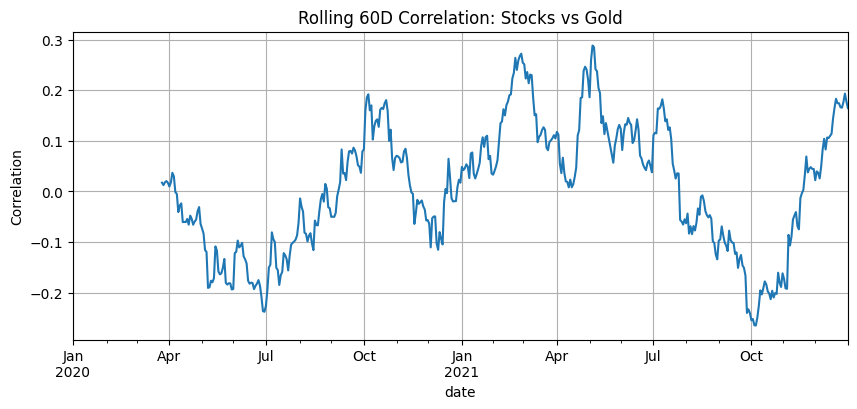

In [132]:
rets = assets.pct_change()
roll_corr_60 = rets["stocks"].rolling(60).corr(rets["gold"])

roll_corr_60.plot(title="Rolling 60D Correlation: Stocks vs Gold")
plt.ylabel("Correlation"); plt.grid(True); plt.show()


Rolling correlations reveal regime shifts (e.g., crisis periods when assets co-move).


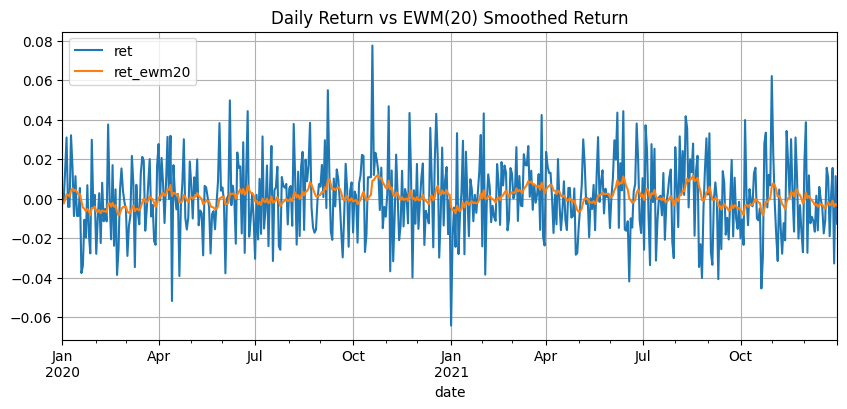

In [133]:
# Expanding = from start to current point (growing window)
aq["ozone_expanding_mean"] = aq["ozone"].expanding(min_periods=10).mean()

# EWM = recent observations get more weight (fades the past)
goog["ret"] = goog["close_price"].pct_change()
goog["ret_ewm20"] = goog["ret"].ewm(span=20, adjust=False).mean()

fig, ax = plt.subplots()
goog[["ret","ret_ewm20"]].plot(ax=ax, title="Daily Return vs EWM(20) Smoothed Return")
ax.grid(True); plt.show()


Use expanding for cumulative KPIs; use EWM (exponentially weighted windows) when you want faster response to new data.

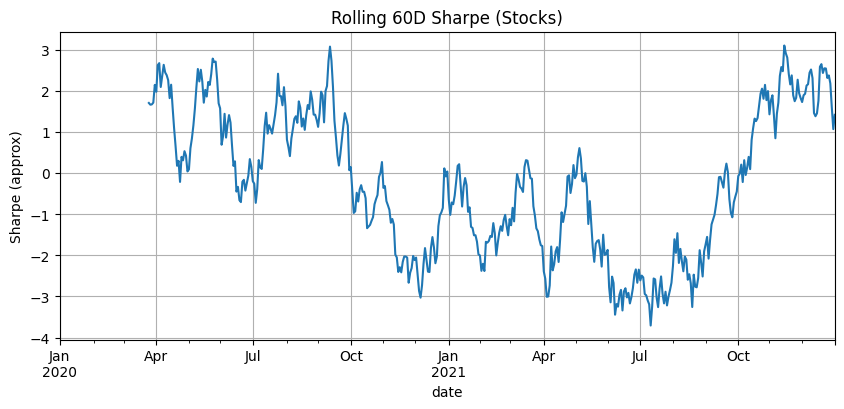

In [134]:
# Rolling Sharpe (mean/std) * sqrt(252) — simple illustration
roll_mean = rets["stocks"].rolling(60).mean()
roll_std  = rets["stocks"].rolling(60).std()
roll_sharpe_60 = (roll_mean / roll_std) * np.sqrt(252)

roll_sharpe_60.plot(title="Rolling 60D Sharpe (Stocks)")
plt.ylabel("Sharpe (approx)"); plt.grid(True); plt.show()


.rolling().apply(func) also lets you plug in any custom function (just watch performance).

#### 🚀 Hands-on Exercises

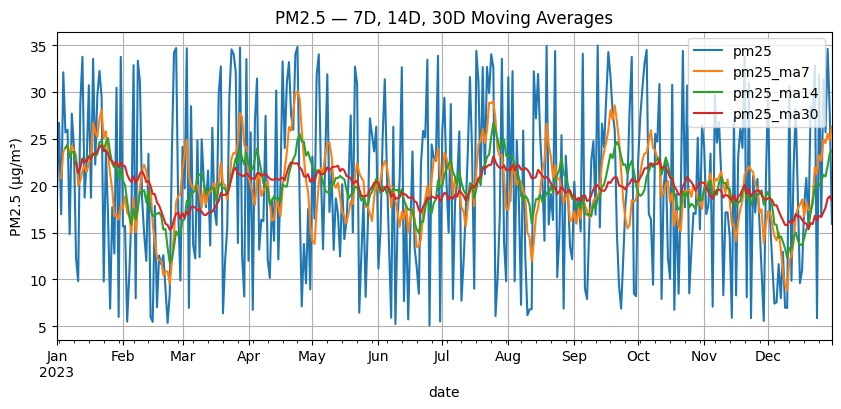

Latest MA values:
             pm25_ma7  pm25_ma14  pm25_ma30
date                                      
2023-12-31     26.29      23.79      18.41


In [135]:
aq = pd.read_csv('data/air_quality_trends_simulated.csv',
                parse_dates=['date'], index_col='date').asfreq('D')
aq['pm25_ma7']  = aq['pm25'].rolling(window=7,  min_periods=3).mean()
aq['pm25_ma14'] = aq['pm25'].rolling(window=14, min_periods=5).mean()
aq['pm25_ma30'] = aq['pm25'].rolling(window=30, min_periods=10).mean()
ax = aq[['pm25','pm25_ma7','pm25_ma14','pm25_ma30']].plot(title='PM2.5 — 7D, 14D, 30D Moving Averages')
ax.set_ylabel('PM2.5 (μg/m³)'); ax.grid(True); plt.show()
print('Latest MA values:\n', aq[['pm25_ma7','pm25_ma14','pm25_ma30']].tail(1).round(2))

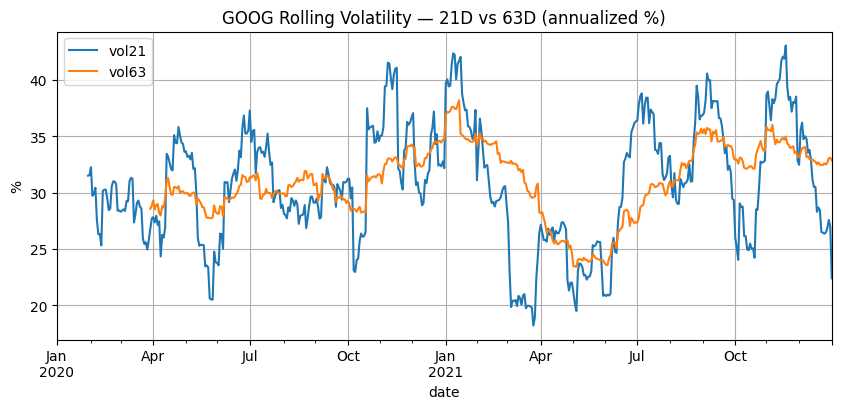

Latest vol21/vol63 (%): 22.394642396563107 32.86732762029726


In [136]:
goog = pd.read_csv('data/goog_simulated.csv',
                parse_dates=['date'], index_col='date').asfreq('B')
ret = goog['close_price'].pct_change()
vol21 = ret.rolling(21).std() * np.sqrt(252) * 100
vol63 = ret.rolling(63).std() * np.sqrt(252) * 100
ax = pd.concat({'vol21':vol21, 'vol63':vol63}, axis=1).plot(title='GOOG Rolling Volatility — 21D vs 63D (annualized %)')
ax.set_ylabel('%'); ax.grid(True); plt.show()
print('Latest vol21/vol63 (%):', float(vol21.iloc[-1]), float(vol63.iloc[-1]))

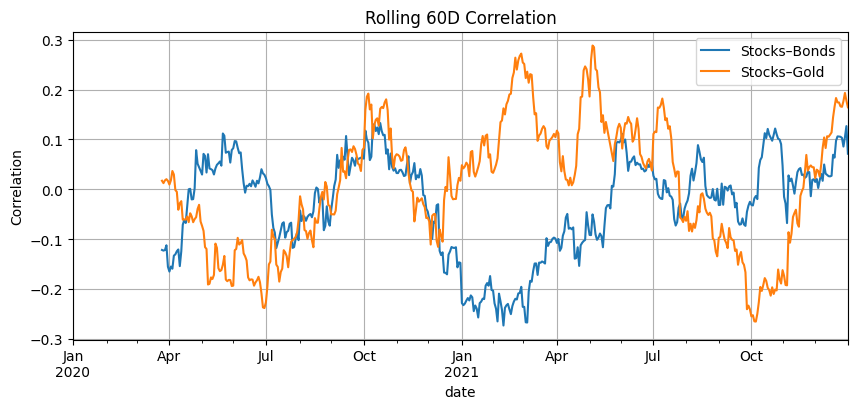

In [137]:
assets = pd.read_csv('data/assets_simulated.csv',
                parse_dates=['date'], index_col='date').asfreq('B') 
rets = assets.pct_change()
corr_sb = rets['stocks'].rolling(60).corr(rets['bonds'])
corr_sg = rets['stocks'].rolling(60).corr(rets['gold'])
ax = pd.concat({'Stocks–Bonds':corr_sb, 'Stocks–Gold':corr_sg}, axis=1).plot(title='Rolling 60D Correlation')
ax.set_ylabel('Correlation'); ax.grid(True); plt.show()

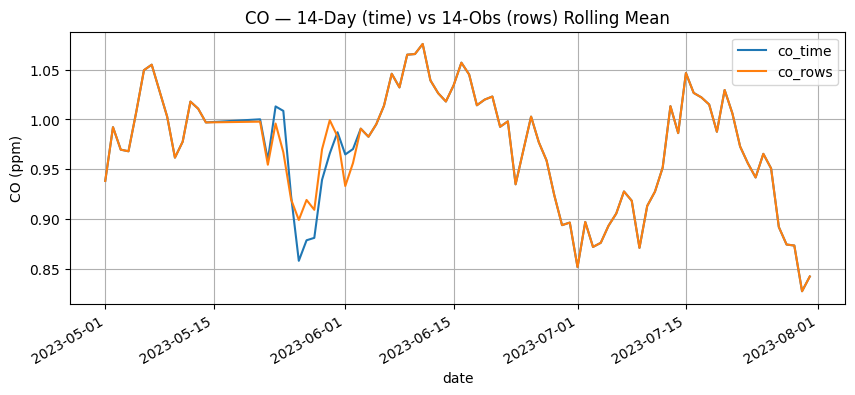

Row-based ignores gaps; time-based respects calendar days.


In [138]:
aq2 = aq.copy()

drop_idx = pd.date_range('2023-05-15','2023-05-20',freq='D')
aq2 = aq2.drop(index=drop_idx, errors='ignore')
co_time = aq2['co'].rolling('14D').mean()
co_rows = aq2['co'].rolling(14).mean()
ax = pd.concat({'co_time':co_time, 'co_rows':co_rows}, axis=1).loc['2023-05-01':'2023-07-31'].plot(title='CO — 14-Day (time) vs 14-Obs (rows) Rolling Mean')
ax.set_ylabel('CO (ppm)'); ax.grid(True); plt.show()
print('Row-based ignores gaps; time-based respects calendar days.')

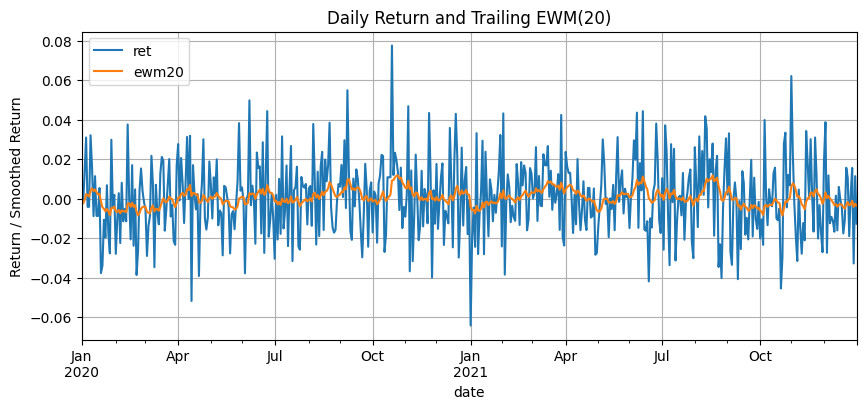

Trailing EWM uses only past data; do not use centered windows for modeling.


In [139]:
ret = goog['close_price'].pct_change()
ewm20 = ret.ewm(span=20, adjust=False).mean()
ax = pd.concat({'ret':ret, 'ewm20':ewm20}, axis=1).plot(title='Daily Return and Trailing EWM(20)')
ax.set_ylabel('Return / Smoothed Return'); ax.grid(True); plt.show()
print('Trailing EWM uses only past data; do not use centered windows for modeling.')

# L10 :Robust Smoothing & Variability: Rolling Median & Rolling Standard Deviation

Rolling median is robust to outliers (spikes).

Rolling mean is sensitive: it will move toward spikes/dips.

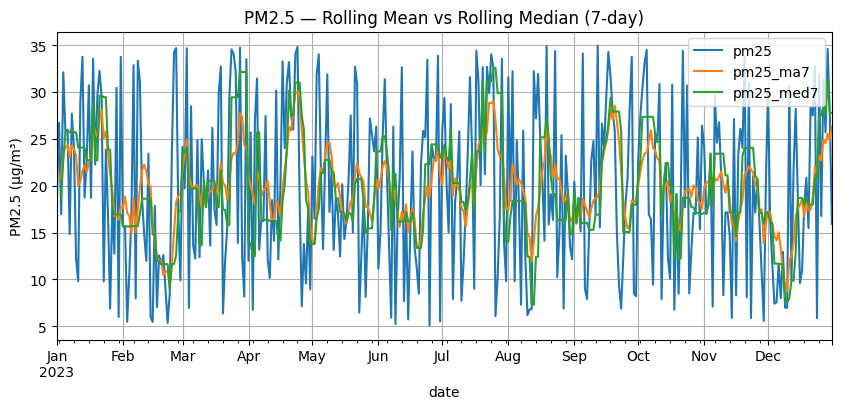

In [140]:
aq = pd.read_csv("data/air_quality_trends_simulated.csv", parse_dates=["date"], index_col="date").asfreq("D")

# Choose a pollutant with occasional spikes (e.g., PM2.5)
aq["pm25_ma7"]   = aq["pm25"].rolling(window=7,  min_periods=3).mean()
aq["pm25_med7"]  = aq["pm25"].rolling(window=7,  min_periods=3).median()

ax = aq[["pm25", "pm25_ma7", "pm25_med7"]].plot(title="PM2.5 — Rolling Mean vs Rolling Median (7-day)")
ax.set_ylabel("PM2.5 (μg/m³)"); ax.grid(True); plt.show()


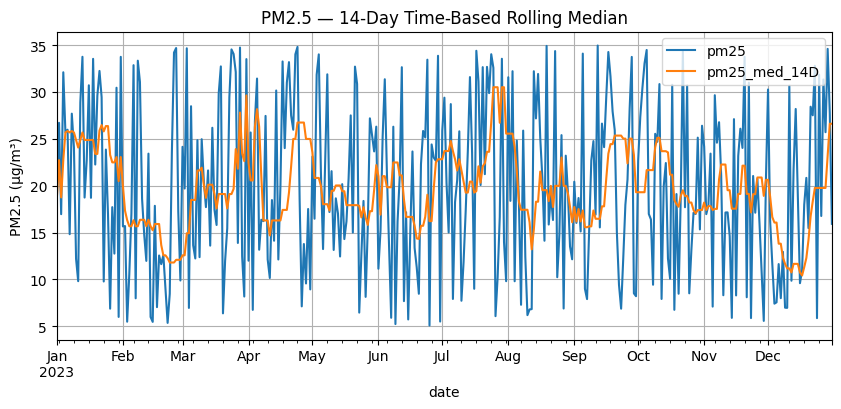

In [141]:
aq["pm25_med_14D"] = aq["pm25"].rolling("14D").median()
aq[["pm25", "pm25_med_14D"]].plot(title="PM2.5 — 14-Day Time-Based Rolling Median")
plt.ylabel("PM2.5 (μg/m³)"); plt.grid(True); plt.show()


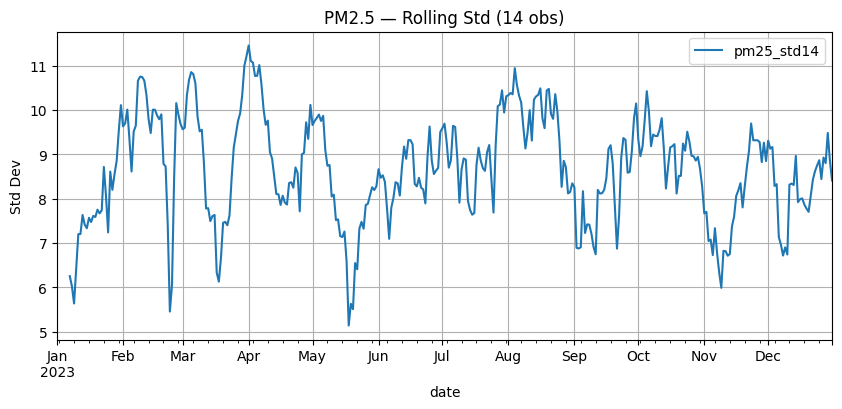

In [142]:
# Local variability over the last 14 observations
aq["pm25_std14"] = aq["pm25"].rolling(14, min_periods=7).std()

ax = aq[["pm25_std14"]].plot(title="PM2.5 — Rolling Std (14 obs)")
ax.set_ylabel("Std Dev"); ax.grid(True); plt.show()


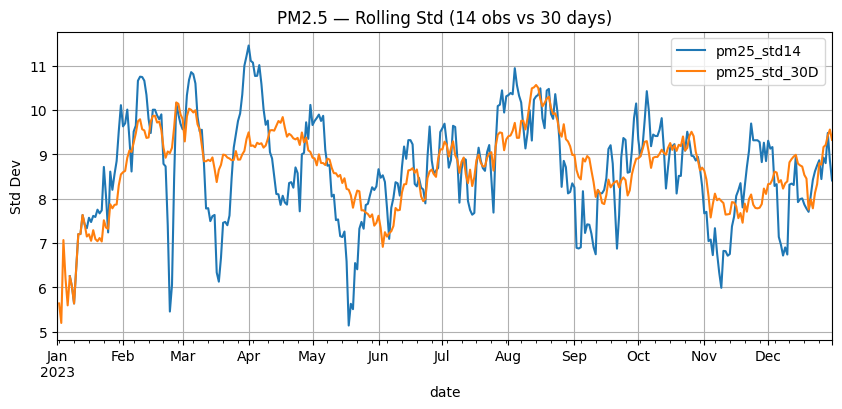

In [143]:
aq["pm25_std_30D"] = aq["pm25"].rolling("30D").std()
aq[["pm25_std14", "pm25_std_30D"]].plot(title="PM2.5 — Rolling Std (14 obs vs 30 days)")
plt.ylabel("Std Dev"); plt.grid(True); plt.show()


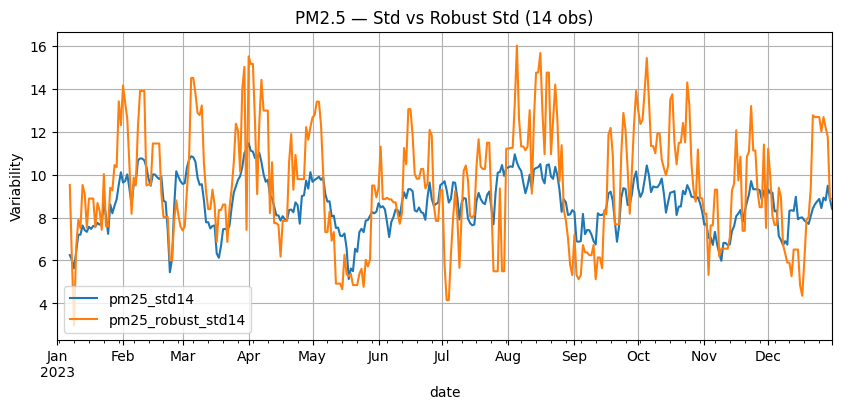

In [144]:
def rolling_mad(s):
    med = np.median(s)
    return np.median(np.abs(s - med))

aq["pm25_mad14"] = aq["pm25"].rolling(14, min_periods=7).apply(rolling_mad, raw=True)
aq["pm25_robust_std14"] = aq["pm25_mad14"] * 1.4826

aq[["pm25_std14", "pm25_robust_std14"]].plot(title="PM2.5 — Std vs Robust Std (14 obs)")
plt.ylabel("Variability"); plt.grid(True); plt.show()


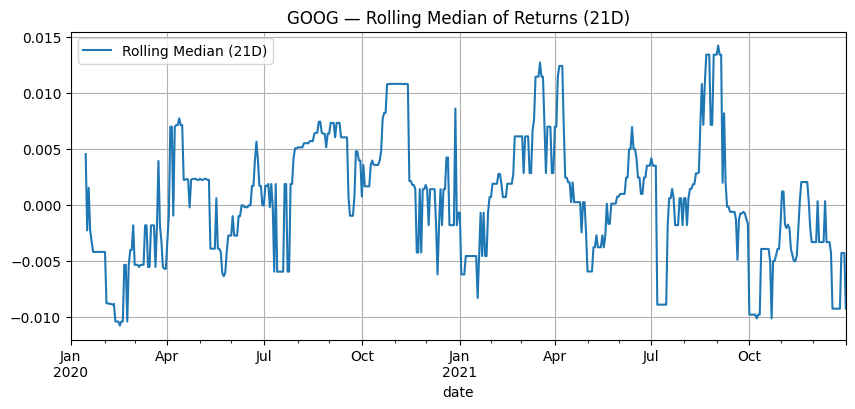

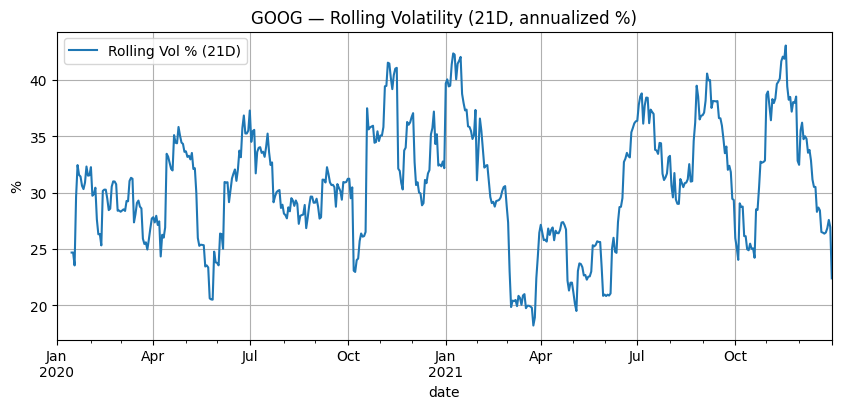

In [145]:
goog = pd.read_csv("data/goog_simulated.csv", parse_dates=["date"], index_col="date").asfreq("B")
ret = goog["close_price"].pct_change()

# Rolling median of returns (robust location)
roll_med_21 = ret.rolling(21, min_periods=10).median()

# Rolling std (volatility), annualized
roll_vol_21 = ret.rolling(21, min_periods=10).std() * np.sqrt(252) * 100

fig, ax = plt.subplots()
pd.concat({"Rolling Median (21D)": roll_med_21}, axis=1).plot(ax=ax, title="GOOG — Rolling Median of Returns (21D)")
ax.grid(True); plt.show()

fig, ax = plt.subplots()
pd.concat({"Rolling Vol % (21D)": roll_vol_21}, axis=1).plot(ax=ax, title="GOOG — Rolling Volatility (21D, annualized %)")
ax.set_ylabel("%"); ax.grid(True); plt.show()


In [146]:
w = 14
baseline = aq["pm25"].rolling(w, min_periods=7).mean()
sigma    = aq["pm25"].rolling(w, min_periods=7).std()
k = 2.5

anomaly_mean = (aq["pm25"] - baseline).abs() > (k * sigma)

# Robust version
baseline_med = aq["pm25"].rolling(w, min_periods=7).median()
mad = aq["pm25"].rolling(w, min_periods=7).apply(rolling_mad, raw=True)
robust_sigma = mad * 1.4826
anomaly_robust = (aq["pm25"] - baseline_med).abs() > (k * robust_sigma)

print("Mean-based anomalies:", int(anomaly_mean.sum()))
print("Robust-based anomalies:", int(anomaly_robust.sum()))


Mean-based anomalies: 0
Robust-based anomalies: 10


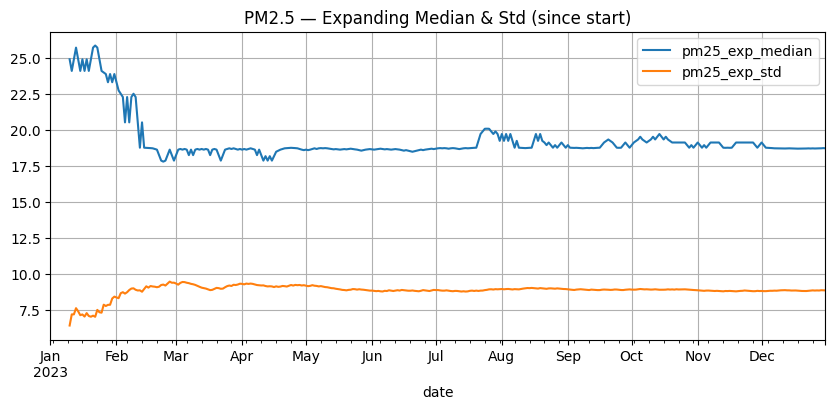

In [147]:
# Expanding median and std from start to current date
aq["pm25_exp_median"] = aq["pm25"].expanding(min_periods=10).median()
aq["pm25_exp_std"]    = aq["pm25"].expanding(min_periods=10).std()

aq[["pm25_exp_median", "pm25_exp_std"]].plot(title="PM2.5 — Expanding Median & Std (since start)")
plt.grid(True); plt.show()


#### 🧪 Hands-on Practice

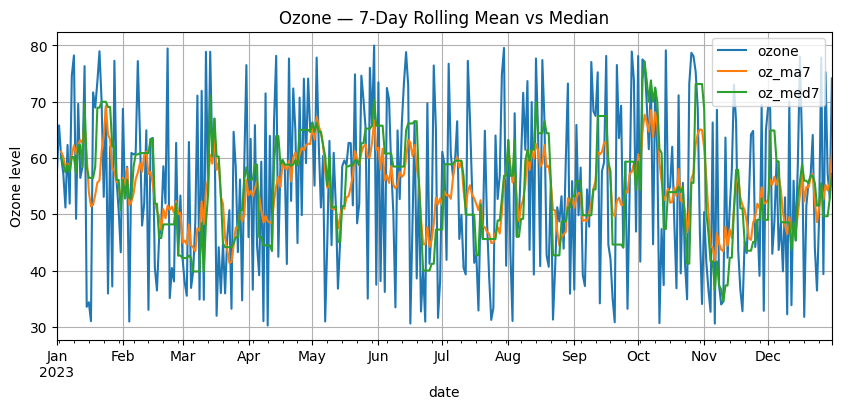

Max divergence date: 2023-01-20  | abs diff = 13.302343701942377


In [148]:
aq = pd.read_csv('data/air_quality_trends_simulated.csv',
                parse_dates=['date'], index_col='date').asfreq('D') 
aq['oz_ma7']  = aq['ozone'].rolling(window=7,  min_periods=3).mean()
aq['oz_med7'] = aq['ozone'].rolling(window=7,  min_periods=3).median()
ax = aq[['ozone','oz_ma7','oz_med7']].plot(title='Ozone — 7-Day Rolling Mean vs Median')
ax.set_ylabel('Ozone level'); ax.grid(True); plt.show()
diff = (aq['oz_ma7'] - aq['oz_med7']).abs(); idxmax = diff.idxmax()
print('Max divergence date:', idxmax.date(), ' | abs diff =', float(diff.loc[idxmax]))

Robust anomalies found: 6


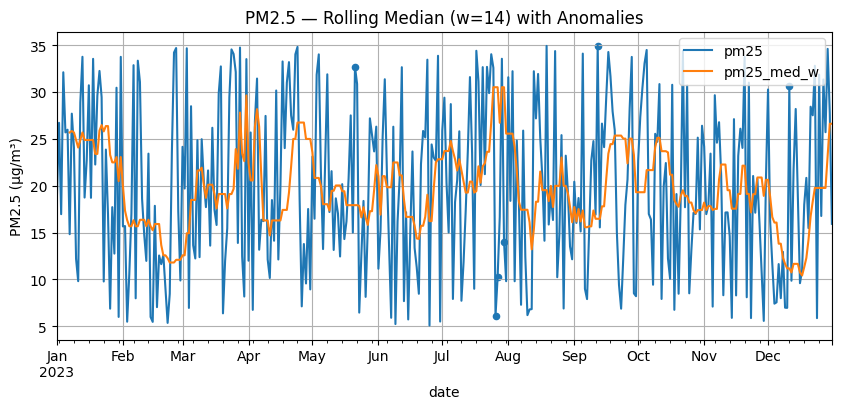

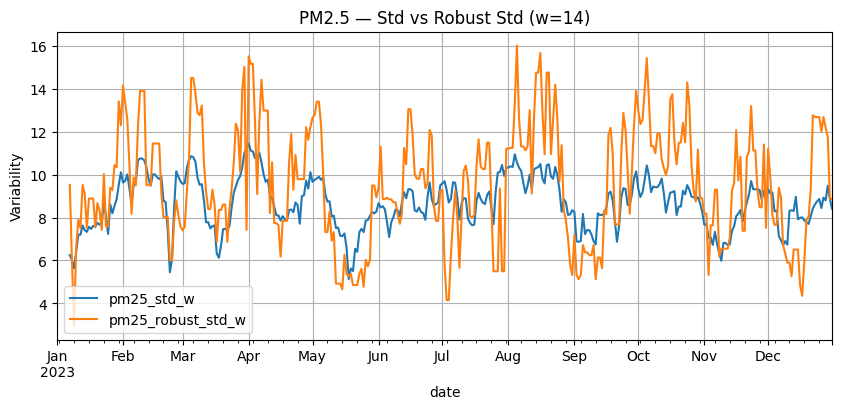

In [149]:
def rolling_mad_array(arr):
    med = np.median(arr)
    return np.median(np.abs(arr - med))
w = 14
aq['pm25_med_w'] = aq['pm25'].rolling(w, min_periods=7).median()
aq['pm25_std_w'] = aq['pm25'].rolling(w, min_periods=7).std()
aq['pm25_mad_w'] = aq['pm25'].rolling(w, min_periods=7).apply(rolling_mad_array, raw=True)
aq['pm25_robust_std_w'] = aq['pm25_mad_w'] * 1.4826
k = 3
anomaly_mask = (aq['pm25'] - aq['pm25_med_w']).abs() > (k * aq['pm25_robust_std_w'])
print('Robust anomalies found:', int(anomaly_mask.sum()))
ax = aq[['pm25','pm25_med_w']].plot(title='PM2.5 — Rolling Median (w=14) with Anomalies')
ax.scatter(aq.index[anomaly_mask], aq.loc[anomaly_mask, 'pm25'], s=20)
ax.set_ylabel('PM2.5 (μg/m³)'); ax.grid(True); plt.show()
ax = aq[['pm25_std_w','pm25_robust_std_w']].plot(title='PM2.5 — Std vs Robust Std (w=14)')
ax.set_ylabel('Variability'); ax.grid(True); plt.show()

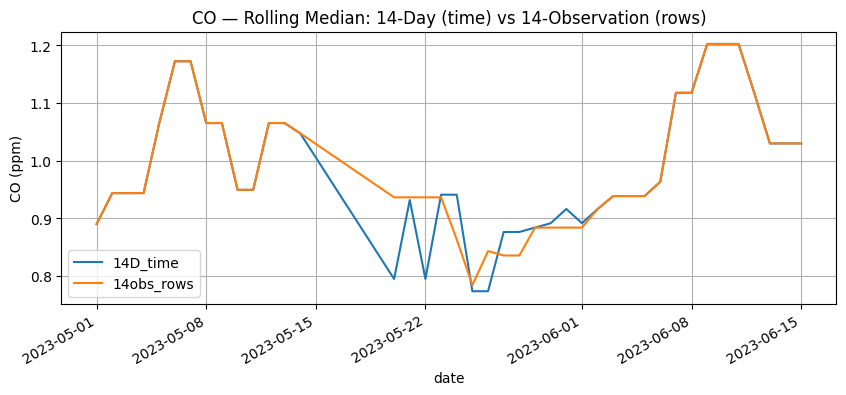

Time-based window respects calendar gaps; row-based ignores missing days.


In [150]:
aq_gap = aq.copy()
aq_gap = aq_gap.drop(index=pd.date_range('2023-05-15','2023-05-19',freq='D'), errors='ignore')
co_time = aq_gap['co'].rolling('14D').median()
co_rows = aq_gap['co'].rolling(14).median()
ax = pd.concat({'14D_time': co_time, '14obs_rows': co_rows}, axis=1).loc['2023-05-01':'2023-06-15'].plot(
    title='CO — Rolling Median: 14-Day (time) vs 14-Observation (rows)')
ax.set_ylabel('CO (ppm)'); ax.grid(True); plt.show()
print('Time-based window respects calendar gaps; row-based ignores missing days.')

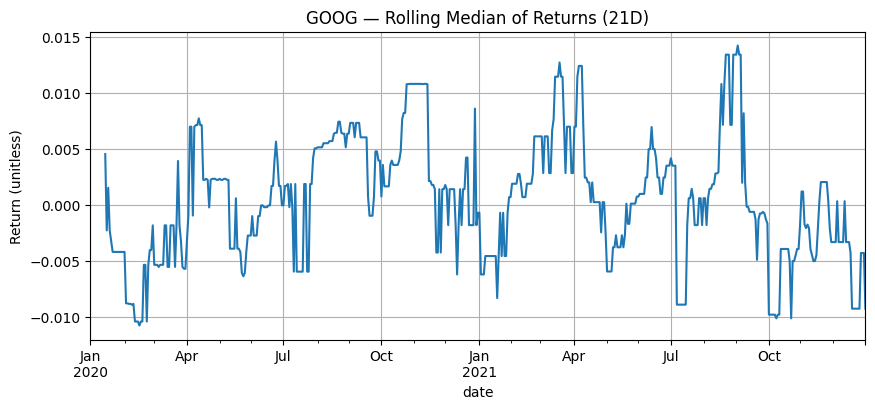

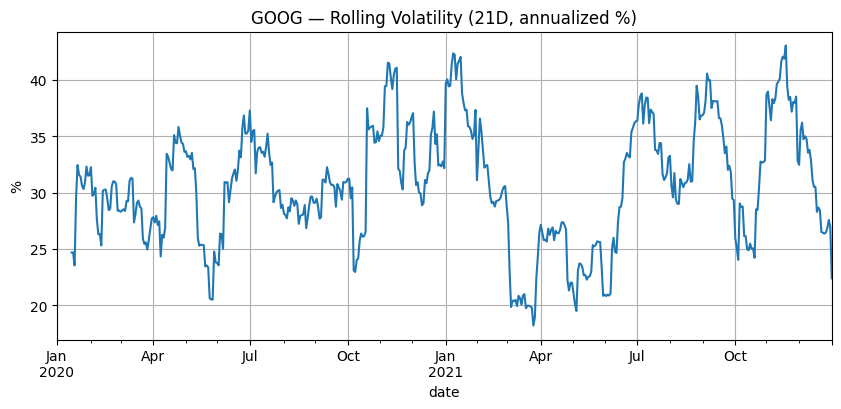

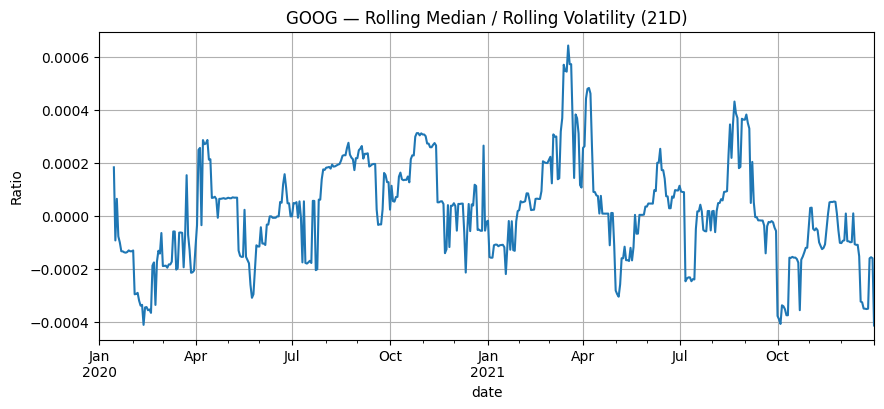

In [151]:
goog = pd.read_csv('data/goog_simulated.csv',
                parse_dates=['date'], index_col='date').asfreq('B') 
ret = goog['close_price'].pct_change()
roll_med_21 = ret.rolling(21, min_periods=10).median()
roll_vol_21 = ret.rolling(21, min_periods=10).std() * np.sqrt(252) * 100
ax = roll_med_21.plot(title='GOOG — Rolling Median of Returns (21D)')
ax.set_ylabel('Return (unitless)'); ax.grid(True); plt.show()
ax = roll_vol_21.plot(title='GOOG — Rolling Volatility (21D, annualized %)')
ax.set_ylabel('%'); ax.grid(True); plt.show()
ratio = roll_med_21 / roll_vol_21.replace(0, np.nan)
ax = ratio.plot(title='GOOG — Rolling Median / Rolling Volatility (21D)')
ax.set_ylabel('Ratio'); ax.grid(True); plt.show()

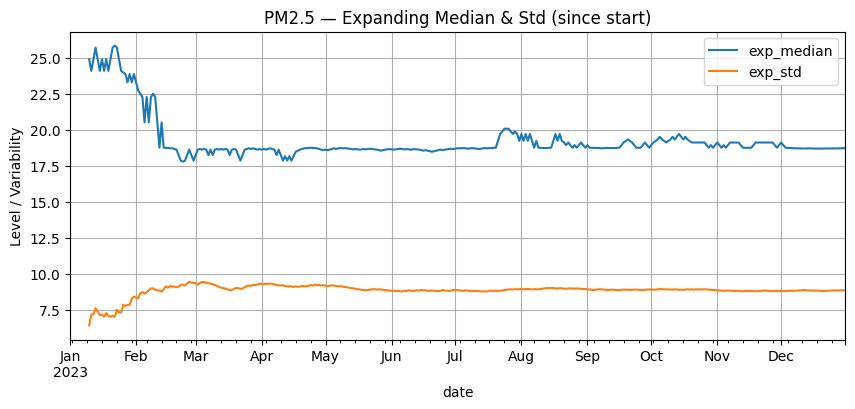

A rising expanding median suggests higher central tendency over the year; expanding std shows cumulative variability.


In [152]:
aq2 = aq.copy()
exp_med = aq2['pm25'].expanding(min_periods=10).median()
exp_std = aq2['pm25'].expanding(min_periods=10).std()
ax = pd.concat({'exp_median': exp_med, 'exp_std': exp_std}, axis=1).plot(
    title='PM2.5 — Expanding Median & Std (since start)')
ax.set_ylabel('Level / Variability'); ax.grid(True); plt.show()
print('A rising expanding median suggests higher central tendency over the year; expanding std shows cumulative variability.')

# L11: Relationships Between Time Series: Correlation

In [153]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (10, 4)

# 1) Load the dataset (same directory as notebook)
df = pd.read_csv("data/assets_simulated.csv", parse_dates=["date"], index_col="date")

# 2) Use returns (pct_change) to avoid spurious correlation from shared trends in price levels
rets = df.pct_change().dropna()
rets.head()


,stocks,bonds,gold,oil
date,,,,
2020-01-02,0.011629,-0.001297,-0.000511,0.003546
2020-01-03,0.003468,0.001415,-0.004537,0.012851
2020-01-06,-0.016686,0.002009,0.002568,0.022405
2020-01-07,-0.006288,-0.003444,-0.009352,-0.008212
2020-01-08,0.019160,0.002280,0.002474,-0.001518


In [154]:
corr_pearson = rets.corr()
corr_pearson

,stocks,bonds,gold,oil
stocks,1.000000,-0.033459,0.004465,-0.006379
bonds,-0.033459,1.000000,0.065448,-0.006140
gold,0.004465,0.065448,1.000000,-0.044776
oil,-0.006379,-0.006140,-0.044776,1.000000


In [155]:
corr_spearman = rets.corr(method="spearman")
corr_spearman

,stocks,bonds,gold,oil
stocks,1.000000,-0.042516,-0.012078,-0.022387
bonds,-0.042516,1.000000,0.069578,-0.013857
gold,-0.012078,0.069578,1.000000,-0.046545
oil,-0.022387,-0.013857,-0.046545,1.000000


In [156]:
corr_pearson.to_csv("corr_pearson_returns.csv")
corr_spearman.to_csv("corr_spearman_returns.csv")


In [157]:
# Correlation of every asset with 'stocks' (as a simple benchmark)
corr_with_stocks = rets.drop(columns="stocks").corrwith(rets["stocks"]).sort_values(ascending=False)
corr_with_stocks


gold     0.004465
oil     -0.006379
bonds   -0.033459
dtype: float64

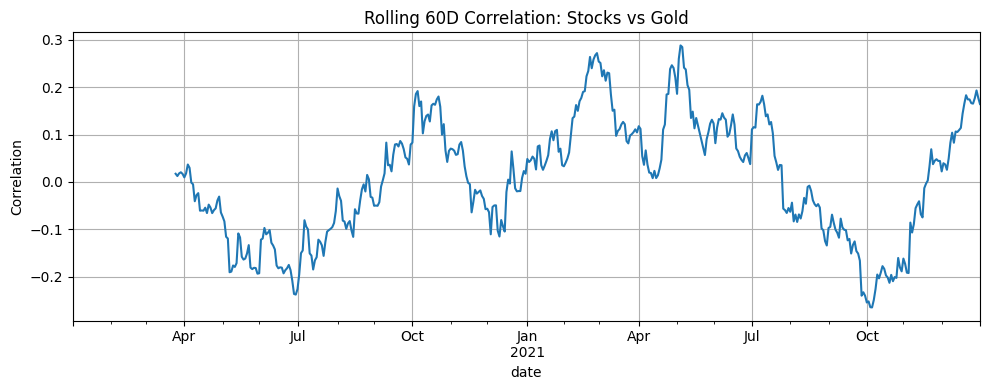

In [158]:
# 60-trading-day rolling correlation between Stocks and Gold
roll_corr_60 = rets["stocks"].rolling(60).corr(rets["gold"])

ax = roll_corr_60.plot(title="Rolling 60D Correlation: Stocks vs Gold")
ax.set_ylabel("Correlation"); ax.grid(True)
plt.tight_layout()
#plt.savefig("rolling_corr_stocks_gold_60d.png", dpi=200, bbox_inches="tight")
plt.show()


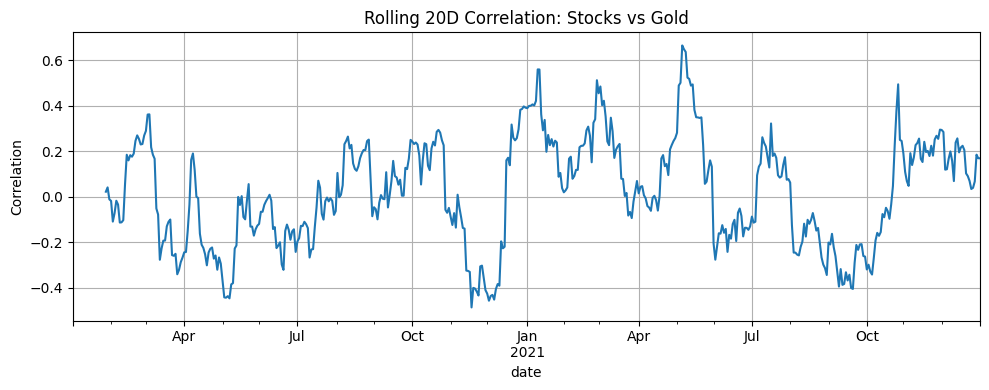

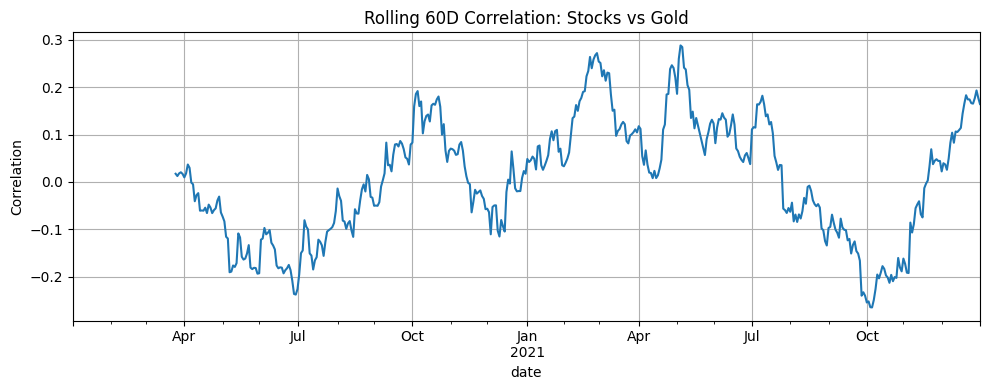

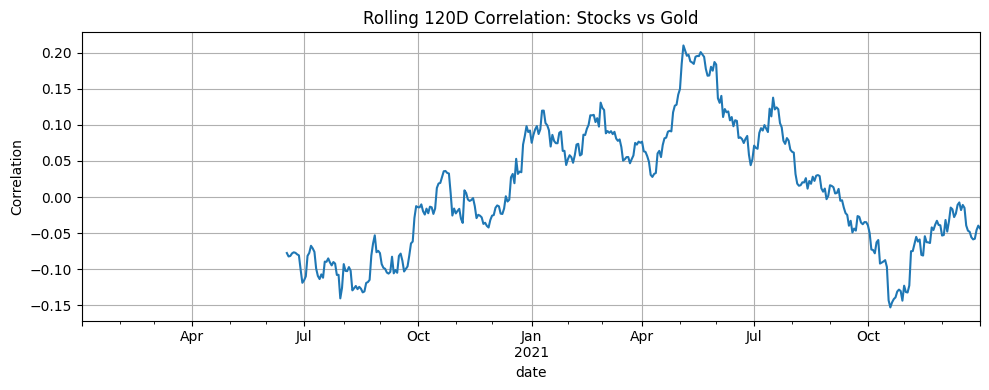

In [159]:
for w in [20, 60, 120]:
    rc = rets["stocks"].rolling(w).corr(rets["gold"])
    ax = rc.plot(title=f"Rolling {w}D Correlation: Stocks vs Gold")
    ax.set_ylabel("Correlation"); ax.grid(True)
    plt.tight_layout()
    plt.savefig(f"rolling_corr_stocks_gold_{w}d.png", dpi=200, bbox_inches="tight")
    plt.show()


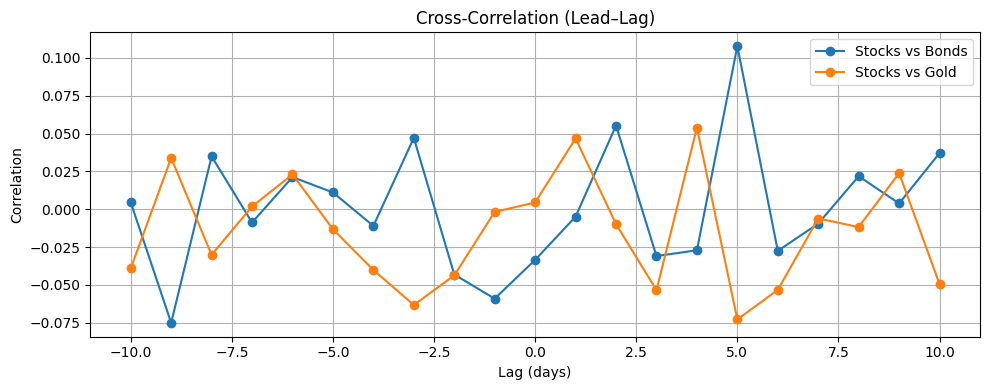

(-10    0.004566
 -9    -0.075093
 -8     0.034929
 -7    -0.008758
 -6     0.021221
 -5     0.011118
 -4    -0.011030
 -3     0.047128
 -2    -0.043131
 -1    -0.059080
  0    -0.033459
  1    -0.004909
  2     0.055301
  3    -0.030916
  4    -0.027124
  5     0.107750
  6    -0.027518
  7    -0.009503
  8     0.021822
  9     0.003820
  10    0.037122
 dtype: float64,
 -10   -0.039147
 -9     0.033852
 -8    -0.030110
 -7     0.001819
 -6     0.023020
 -5    -0.013187
 -4    -0.040117
 -3    -0.063238
 -2    -0.043729
 -1    -0.001737
  0     0.004465
  1     0.046787
  2    -0.009827
  3    -0.053478
  4     0.053911
  5    -0.072795
  6    -0.053286
  7    -0.006123
  8    -0.011733
  9     0.023847
  10   -0.049521
 dtype: float64)

In [160]:
def xcorr(a, b, max_lag=10):
    """
    Cross-correlation by simple shifting.
    Returns a Series indexed by lag:
      negative lag -> 'a' leads 'b'
      positive lag -> 'b' leads 'a'
    """
    out = {}
    for L in range(-max_lag, max_lag + 1):
        if L < 0:   # a leads b
            out[L] = a.shift(-L).corr(b)
        else:       # b leads a
            out[L] = a.corr(b.shift(L))
    return pd.Series(out)

xc_sb = xcorr(rets["stocks"], rets["bonds"], max_lag=10)
xc_sg = xcorr(rets["stocks"], rets["gold"],  max_lag=10)

ax = xc_sb.plot(marker="o", label="Stocks vs Bonds")
xc_sg.plot(ax=ax, marker="o", label="Stocks vs Gold")
ax.set_title("Cross-Correlation (Lead–Lag)")
ax.set_xlabel("Lag (days)"); ax.set_ylabel("Correlation")
ax.grid(True); ax.legend()
plt.tight_layout()
#plt.savefig("cross_correlation_lead_lag.png", dpi=200, bbox_inches="tight")
plt.show()

xc_sb, xc_sg


In [161]:
split = "2021-01-01"
corr_pre  = rets.loc[:split].corr()
corr_post = rets.loc[split:].corr()

corr_pre, corr_post


(          stocks     bonds      gold       oil
 stocks  1.000000 -0.063933 -0.017242  0.048241
 bonds  -0.063933  1.000000  0.037762 -0.072970
 gold   -0.017242  0.037762  1.000000 -0.066663
 oil     0.048241 -0.072970 -0.066663  1.000000,
           stocks     bonds      gold       oil
 stocks  1.000000 -0.003697  0.030736 -0.061453
 bonds  -0.003697  1.000000  0.104789  0.084988
 gold    0.030736  0.104789  1.000000 -0.024954
 oil    -0.061453  0.084988 -0.024954  1.000000)

# L12: Build a Value-Weighted Index (Market-Cap Weighted)

In [162]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True

# File paths (update if needed)
PATH_COMPONENTS = "data/index_components_list.csv"
PATH_PRICES     = "data/index_prices.csv"
PATH_BENCH      = "data/benchmark.csv"

In [163]:
components = pd.read_csv(PATH_COMPONENTS, parse_dates=["listing_date"])
components


,ticker,name,sector,country,shares_outstanding_m,listing_date
0,ALP,Alpine Tech,Technology,US,820,2015-06-01
1,BEE,Bee Energy,Energy,US,540,2017-03-15
2,CRN,Crania Health,Healthcare,US,310,2016-10-30
3,DYN,Dynamo Motors,Automotive,US,470,2014-01-01
4,EKO,Ekosystems,Industrials,US,260,2018-07-12
5,FYN,FynCloud,Technology,US,900,2013-05-01


In [164]:
# Basic checks (info still fine)
components.info()

# Describe only numeric columns (works on all pandas versions)
desc = components.select_dtypes(include=np.number).describe()
print(desc)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   ticker                6 non-null      object        
 1   name                  6 non-null      object        
 2   sector                6 non-null      object        
 3   country               6 non-null      object        
 4   shares_outstanding_m  6 non-null      int64         
 5   listing_date          6 non-null      datetime64[ns]
dtypes: datetime64[ns](1), int64(1), object(4)
memory usage: 420.0+ bytes
       shares_outstanding_m
count              6.000000
mean             550.000000
std              262.144998
min              260.000000
25%              350.000000
50%              505.000000
75%              750.000000
max              900.000000


In [165]:
universe = components["ticker"].tolist()
print("Universe:", universe)
components[["ticker","name","sector","shares_outstanding_m"]]


Universe: ['ALP', 'BEE', 'CRN', 'DYN', 'EKO', 'FYN']


,ticker,name,sector,shares_outstanding_m
0,ALP,Alpine Tech,Technology,820
1,BEE,Bee Energy,Energy,540
2,CRN,Crania Health,Healthcare,310
3,DYN,Dynamo Motors,Automotive,470
4,EKO,Ekosystems,Industrials,260
5,FYN,FynCloud,Technology,900


In [166]:
prices = pd.read_csv(PATH_PRICES, parse_dates=["date"], index_col="date")
prices = prices[universe].asfreq("B")  # ensure business-day calendar
prices.tail()


,ALP,BEE,CRN,DYN,EKO,FYN
date,,,,,,
2023-12-25,51.889531,69.585779,86.948501,45.534323,79.558770,27.287924
2023-12-26,52.347250,68.748473,87.563057,47.311982,82.852888,27.035878
2023-12-27,53.389556,69.930321,87.151216,47.508907,82.584293,26.851856
2023-12-28,52.257387,70.042631,89.802219,47.009704,82.839554,27.549085
2023-12-29,52.823809,71.330671,90.276587,45.947988,81.366276,28.484911


In [167]:
shares = components.set_index("ticker")["shares_outstanding_m"] * 1_000_000
shares


ticker
ALP    820000000
BEE    540000000
CRN    310000000
DYN    470000000
EKO    260000000
FYN    900000000
Name: shares_outstanding_m, dtype: int64

In [168]:
mv = prices.mul(shares, axis=1)  # MV_{i,t} = Price_{i,t} * Shares_i
mv.head()


,ALP,BEE,CRN,DYN,EKO,FYN
date,,,,,,
2021-01-01,9.023584e+10,2.960889e+10,2.491205e+10,2.135765e+10,1.542449e+10,3.122798e+10
2021-01-04,9.064466e+10,2.939370e+10,2.463680e+10,2.129589e+10,1.560209e+10,3.048678e+10
2021-01-05,9.033527e+10,2.958158e+10,2.462346e+10,2.077376e+10,1.579135e+10,3.106927e+10
2021-01-06,8.926109e+10,2.928196e+10,2.502671e+10,2.029287e+10,1.573894e+10,3.092749e+10
2021-01-07,8.873414e+10,2.860767e+10,2.534168e+10,2.044156e+10,1.575356e+10,3.126989e+10


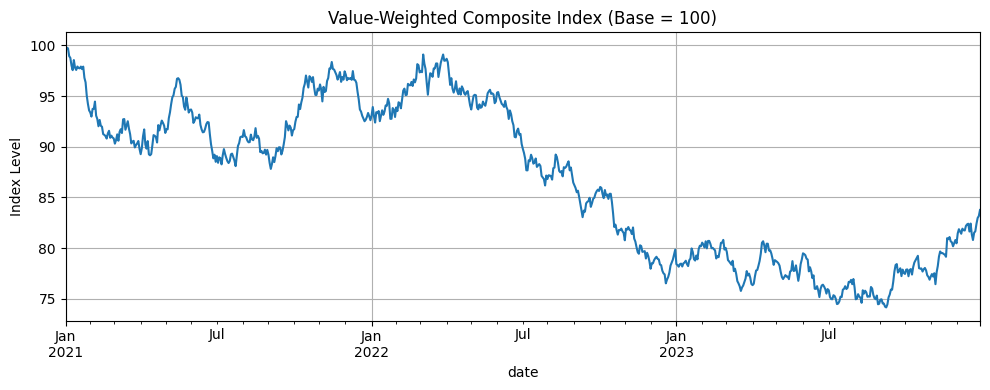

In [169]:
tv = mv.sum(axis=1)                         # total market value
base = tv.iloc[0]
index_level = 100 * tv / base               # base 100

ax = index_level.plot(title="Value-Weighted Composite Index (Base = 100)")
ax.set_ylabel("Index Level")
plt.tight_layout()
#plt.savefig("index_level.png", dpi=200, bbox_inches="tight")
plt.show()


In [170]:
idx_ret = index_level.pct_change().dropna()
ann_factor = 252

cagr = (index_level.iloc[-1] / index_level.iloc[0]) ** (ann_factor/len(idx_ret)) - 1
vol  = idx_ret.std() * np.sqrt(ann_factor)

# Max drawdown
roll_max = index_level.cummax()
drawdown = index_level/roll_max - 1
mdd = drawdown.min()

perf = pd.Series({"CAGR": cagr, "Ann. Volatility": vol, "Max Drawdown": mdd})
perf


CAGR              -0.055657
Ann. Volatility    0.104306
Max Drawdown      -0.258625
dtype: float64

In [171]:
weights = mv.div(tv, axis=0)                       # w_{i,t}
asset_ret = prices.pct_change().reindex_like(weights)

# Shift weights by 1 day so they are "as of" previous close
contrib = weights.shift(1) * asset_ret             # contribution time series
daily_contrib = contrib.sum(axis=1)                # should approx index return
check = pd.concat([idx_ret.rename("index_ret"), daily_contrib.rename("sum_contrib")], axis=1).dropna()
check.head()

# Cumulative contribution per asset (since inception)
cum_contrib = contrib.fillna(0).cumsum()
cum_contrib.tail()


,ALP,BEE,CRN,DYN,EKO,FYN
date,,,,,,
2023-12-25,-0.243938,0.051214,0.012484,-0.001904,0.028874,-0.032711
2023-12-26,-0.241777,0.048611,0.013581,0.002905,0.033804,-0.034017
2023-12-27,-0.236902,0.052251,0.012852,0.003433,0.033406,-0.034962
2023-12-28,-0.242161,0.052595,0.017508,0.002104,0.033782,-0.031407
2023-12-29,-0.239536,0.056526,0.018339,-0.000716,0.031617,-0.026647


In [172]:
bench = pd.read_csv(PATH_BENCH, parse_dates=["date"], index_col="date")["benchmark"].asfreq("B")
bench_ret = bench.pct_change().dropna()

aligned = pd.concat([idx_ret.rename("index"), bench_ret.rename("benchmark")], axis=1).dropna()
aligned.corr()


,index,benchmark
index,1.000000,0.061089
benchmark,0.061089,1.000000


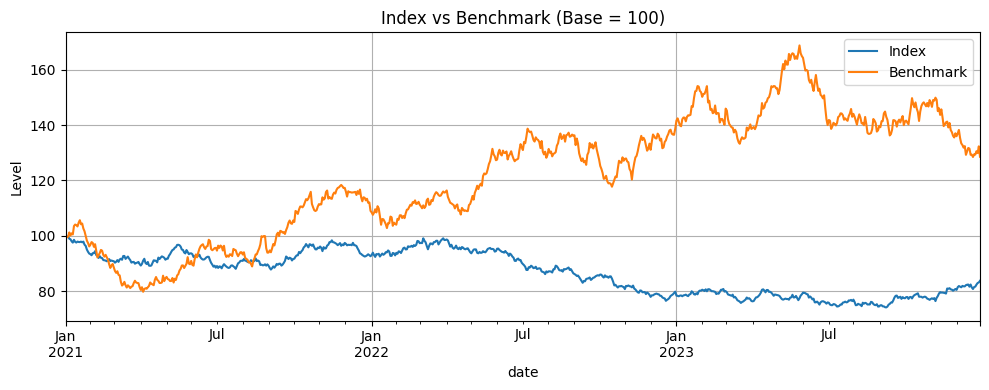

In [173]:
ax = pd.concat({"Index": index_level, "Benchmark": 100*bench/bench.iloc[0]}, axis=1).dropna() \
       .plot(title="Index vs Benchmark (Base = 100)")
ax.set_ylabel("Level")
plt.tight_layout(); #plt.savefig("index_vs_benchmark_level.png", dpi=200, bbox_inches="tight"); 
plt.show()


In [174]:
excess = aligned["index"] - aligned["benchmark"]
tracking_error = excess.std() * np.sqrt(252)

# Simple beta via covariance/variance
beta = aligned.cov().loc["index","benchmark"] / aligned["benchmark"].var()

metrics2 = pd.Series({"Tracking Error (ann.)": tracking_error, "Beta": beta})
metrics2


Tracking Error (ann.)    0.219702
Beta                     0.031885
dtype: float64

In [175]:
# Correlation among constituents (returns)
const_corr = prices.pct_change().corr()
const_corr


,ALP,BEE,CRN,DYN,EKO,FYN
ALP,1.000000,-0.063383,0.018790,-0.023226,0.012569,0.037409
BEE,-0.063383,1.000000,-0.018807,-0.036295,-0.014027,0.048411
CRN,0.018790,-0.018807,1.000000,0.043252,0.067888,0.050748
DYN,-0.023226,-0.036295,0.043252,1.000000,-0.017452,0.001298
EKO,0.012569,-0.014027,0.067888,-0.017452,1.000000,0.045796
FYN,0.037409,0.048411,0.050748,0.001298,0.045796,1.000000


In [177]:
with pd.ExcelWriter("index_analysis.xlsx", engine="xlsxwriter") as xl:
    index_level.to_frame("index_level").to_excel(xl, sheet_name="IndexLevel")
    perf.to_frame("value").to_excel(xl, sheet_name="Performance")
    metrics2.to_frame("value").to_excel(xl, sheet_name="BenchmarkMetrics")
    weights.to_excel(xl, sheet_name="Weights")
    cum_contrib.to_excel(xl, sheet_name="CumContrib")
    const_corr.to_excel(xl, sheet_name="ConstituentCorr")
    aligned.to_excel(xl, sheet_name="IndexVsBenchmark")
print("Saved: index_analysis.xlsx")


Saved: index_analysis.xlsx


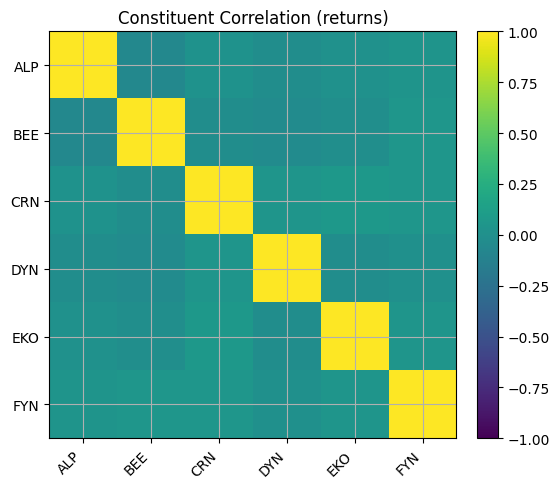

In [178]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6,5))
im = ax.imshow(const_corr.values, vmin=-1, vmax=1)
ax.set_xticks(range(len(const_corr.columns))); ax.set_xticklabels(const_corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(const_corr.index)));  ax.set_yticklabels(const_corr.index)
ax.set_title("Constituent Correlation (returns)")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig("constituent_correlation_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()
